<a href="https://colab.research.google.com/github/Melonangie/Galaxy-Vision/blob/main/modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelado y selección de modelos para predecir la morfología de galaxias MaNGA

**Objetivo.** Predecir la morfología visual de Hubble (T-type) de ~9 900 galaxias MaNGA a partir de su **espectro integrado en todo el campo de visión (FoV)**. Partimos del *baseline* (`results/FoV-OUT_baseline`) y de las *features* (`results/FoV-OUT_features_results`) del repositorio Galaxy-Vision.

| Tarea de CRISP-ML(Q) | Dónde se hace aquí |
|---|---|
| Investigación de literatura sobre problemas similares | Celdas 2–3 |
| Definir medidas de calidad del modelo (Tabla 2: rendimiento, robustez, escalabilidad, explicabilidad, complejidad, recursos) | Celda 4 y Parte 6 |
| Selección de modelo: empezar con baja capacidad y subirla paso a paso (*no free lunch*) | Escalera M0 → M9 |
| Incorporar conocimiento del dominio | Features físicas, modelo ordinal, CNN sobre el espectro en reposo |
| Entrenamiento con regularización y validación cruzada | `evaluar()`, búsqueda en rejilla |
| Ensambles e incertidumbre | M8 y curva cobertura–exactitud |
| Reproducibilidad del método y del resultado (semillas, varias corridas, media ± varianza) | `SEMILLAS`, prueba t corregida, JSON final |
| Evaluación en un test ciego, sin fugas | Parte 7 (una sola vez) |
| Rendimiento por segmentos (*slices*) | Por clase, por inclinación, S/N, z y masa |
| Robustez ante ruido y datos faltantes | `perturbar()` |
| Explicabilidad validada por un experto | Importancia por permutación, PDP, oclusión espectral |
| Comparar con los criterios de éxito y decidir si regresar a una fase previa | Lista de verificación final |

## 1. Morfología de galaxias: qué queremos predecir y por qué el espectro la contiene

### 1.1 La secuencia de Hubble y el T-type
- **Hubble (1926, ApJ 64, 321; 1936, *The Realm of the Nebulae*)** clasificó las galaxias en elípticas (E), lenticulares (S0), espirales (Sa→Sc, con o sin barra) e irregulares. El diagrama "diapasón" ordena las espirales por tres criterios: el tamaño relativo del bulbo, el enrollamiento de los brazos y su resolución en regiones HII.
- **de Vaucouleurs (1959, Handb. Phys. 53, 275)** extendió el esquema (Sd, Sm, Im) y lo hizo numérico con el **T-type**. En el RC3 (de Vaucouleurs et al. 1991) va de E = −5, S0 = −2…0, Sa = 1, Sb = 3, Sc = 5, Sd = 7, Sm = 9 a Im = 10.
- **Sandage (1961, *Hubble Atlas*; 2005, ARA&A 43, 581)**, **Buta (2013, *Secular Evolution of Galaxies*)**, **van den Bergh (1976, ApJ 206, 883)** y **Kormendy & Bender (2012, ApJS 198, 2)** revisan el esquema. Las S0 forman una secuencia paralela a las espirales.
- **Cappellari et al. (2011, MNRAS 416, 1680; 2016, ARA&A 54, 597)** y **Emsellem et al. (2011, MNRAS 414, 888)**, con espectroscopía de campo integral (ATLAS3D), muestran que la mayoría de las "elípticas" y S0 son **rotadores rápidos**, cinemáticamente parecidos a las espirales. Por eso **E y S0 son difíciles de separar incluso para un experto**.

### 1.2 Correlaciones físicas que hacen posible la predicción desde el espectro
A lo largo de la secuencia de Hubble cambian varias propiedades (**Roberts & Haynes 1994, ARA&A 32, 115**):

| Propiedad | Tempranas (E/S0) | Tardías (Sc–Im) | Rasgo espectral (vacío, Å) |
|---|---|---|---|
| Edad de la población estelar | vieja (>5 Gyr) | joven/mixta | Salto D4000, Hδ_A, banda G 4305 (Kauffmann et al. 2003a) |
| Metalicidad / α-elementos | alta | baja | Mgb 5177, Fe5270, NaD 5894 |
| Formación estelar | casi nula | alta | EW(Hα 6564.6), [OII] 3728.5 (Kennicutt 1992, ApJS 79, 255; 1998, ARA&A 36, 189) |
| Gas ionizado / AGN | LINER/retirada | HII | [NII]/Hα, [OIII]/Hβ (BPT; Baldwin et al. 1981; Kewley et al. 2006) |
| Polvo | poco | más | Decremento de Balmer Hα/Hβ |
| Color | rojo | azul | Pendiente del continuo (Strateva et al. 2001, AJ 122, 1861; Baldry et al. 2004) |
| Masa estelar | alta | baja | Dispersión de velocidades, Mgb (Kauffmann et al. 2003b) |

La **bimodalidad** de las galaxias (Strateva 2001; Baldry 2004; Blanton & Moustakas 2009, ARA&A 47, 159) hace que la separación temprana/tardía sea "fácil". Las subclases (Sa vs Sab vs Sb) dependen de **estructura**, como el bulbo y los brazos, que el espectro solo ve de forma indirecta (Conselice 2014, ARA&A 52, 291).

### 1.3 Por qué la morfología no es solo un problema de colores
- **Densidad del entorno** (Dressler 1980, ApJ 236, 351): las tempranas dominan en cúmulos.
- **Evolución secular** (Kormendy & Kennicutt 2004, ARA&A 42, 603): las barras y los pseudobulbos cambian el tipo sin cambiar mucho el espectro.
- **Apagado morfológico** (Martig et al. 2009, ApJ 707, 250) y apagado por masa/entorno (Peng et al. 2010, ApJ 721, 193): existen **espirales rojas** (Masters et al. 2010a, MNRAS 405, 783) y **elípticas azules** (Schawinski et al. 2009, MNRAS 396, 818). Son la población que **ningún modelo espectral clasificará bien**. Ver también el "valle verde" (Schawinski et al. 2014, MNRAS 440, 889).
- **Inclinación** (Masters et al. 2010b, MNRAS 404, 792): una espiral de canto se ve más roja y con más polvo, así que el cociente b/a es una variable de confusión.
- **Efectos de apertura** (Kewley et al. 2005, PASP 117, 227): con una fibra solo se ve el bulbo. MaNGA cubre hasta 1.5–2.5 Rₑ, de modo que el espectro FoV integra bulbo + disco y reduce este sesgo.

### 1.4 Ruido intrínseco de las etiquetas (el "techo")
Los clasificadores humanos expertos difieren en **σ ≈ 1.3–2 unidades de T** (**Naim et al. 1995, MNRAS 274, 1107**; **Lahav et al. 1995, Science 267, 859**). Galaxy Zoo (**Lintott et al. 2008, MNRAS 389, 1179**) y **Nair & Abraham (2010, ApJS 186, 427)** cuantifican esta dispersión. El baseline estimó un **techo σ=1.3** (BA máxima alcanzable ≈ 0.41 / 0.83 / 0.70 para detallado / tres clases / intervalos). **No podemos esperar exactitudes cercanas a 1 en el esquema detallado.**

### 1.5 Etiquetas usadas: MaNGA Visual Morphology
**Vázquez-Mata et al. (2022, MNRAS 512, 2222; DR15)** y **Vázquez-Mata et al. (2025, MNRAS 544, 1056; DR17, 10 059 galaxias, 13 tipos)** clasificaron visualmente imágenes profundas (DESI Legacy y SDSS) con procesamiento de imagen avanzado. MaNGA está descrito en **Bundy et al. (2015, ApJ 798, 7)**, **Drory et al. (2015, AJ 149, 77)**, **Law et al. (2016, AJ 152, 83**; pipeline DRP, longitudes de onda en **vacío**), **Wake et al. (2017, AJ 154, 86)** y **Abdurro'uf et al. (2022, ApJS 259, 35; DR17)**. Los redshifts provienen del NSA (**Blanton et al. 2011, AJ 142, 31**).

**Conclusión de la sección.** El espectro integrado contiene información fuerte sobre la **población estelar y el gas**, que correlaciona con el tipo de Hubble. En cambio, la información **estructural** (barras, brazos, bulbo/disco) llega de forma indirecta. Por eso esperamos un rendimiento alto en el esquema de **3 clases**, intermedio en **intervalos** y limitado por el ruido de etiqueta en el **detallado**.

## 2. Investigación de literatura

| Trabajo | Datos | Método | Resultado relevante |
|---|---|---|---|
| Naim et al. 1995; Lahav et al. 1995 | Imágenes (APM) | Redes neuronales | Alcanza la dispersión entre expertos (σ_T≈1.8) |
| Sánchez Almeida et al. 2010, ApJ 714, 487 | Espectros SDSS | k-means (no supervisado) | Las clases espectrales se alinean con los tipos de Hubble |
| Huertas-Company et al. 2008, A&A 478, 971; 2011, A&A 525, A157 | Parámetros + color | SVM, probabilidades bayesianas | Separación temprana/tardía ~80 % |
| Domínguez Sánchez et al. 2018, MNRAS 476, 3661; 2022, MNRAS 509, 4024 | Imágenes SDSS/MaNGA | CNN | T-type con σ ≈ 1.1–1.5; catálogo para MaNGA DR17 |
| Portillo et al. 2020, AJ 160, 45 | Espectros SDSS | Autoencoder variacional | Un espacio latente de 6 dimensiones separa formación estelar, AGN y quiescentes |
| Teimoorinia et al. 2022, AJ | Espectros MaNGA | Aprendizaje profundo no supervisado | Clases espectrales ligadas a la morfología |
| Zhong et al. 2024 (GaSNet-II), MNRAS 532, 643 | Espectros SDSS | CNN 1D | Clasificación y redshift con CNN unidimensional |
| Aguilar-Argüello et al. 2025, MNRAS 537, 876 | Parámetros estructurales + color de MaNGA | XGBoost + SHAP | 88 % (2 clases), 65 % (5 clases) |
| Grinsztajn, Oyallon & Varoquaux 2022, NeurIPS | Datos tabulares | Árboles vs. redes | En datos tabulares los árboles igualan o superan a las redes profundas |
| Hollmann et al. 2025, Nature 637, 319 | Datos tabulares | TabPFN (transformer preentrenado) | Fuerte en conjuntos pequeños y medianos |

**Conclusión.** En la literatura los modelos de **imagen** llegan al nivel humano. Con **espectros** se separan bien las familias (temprana/tardía), pero las subclases finas se degradan. Para datos tabulares, los modelos lineales regularizados y los de árboles son competitivos frente a las redes. Esto justifica una escalera de capacidad que empiece en la regresión logística (el baseline).

## 3. Medidas de calidad y criterios de éxito (definidos ANTES de modelar)

CRISP-ML(Q) (Tabla 2) pide definir las medidas de calidad antes de entrenar, para no "mover la portería" después.

| Medida | Cómo se mide aquí | Peso en el puntaje |
|---|---|---|
| **Rendimiento** | Exactitud balanceada (BA) media en CV 5×3 (5 pliegues × 3 semillas) | 0.40 |
| **Robustez** | Fracción de BA conservada con ruido gaussiano (0.25σ) y con 10 % de NaN | 0.20 |
| **Explicabilidad** | Escala 0–1 (Rudin 2019, Nat. Mach. Intell. 1, 206): modelos lineales y ordinales = 1, árboles = 0.5, redes = 0.2 | 0.15 |
| **Complejidad** | log₁₀(número de parámetros) | 0.10 |
| **Recursos** | ms por galaxia al predecir | 0.10 |
| **Escalabilidad** | Tiempo de entrenamiento | 0.05 |

**Regla de selección.** Primero se forma el conjunto de modelos **estadísticamente empatados** con el mejor en BA: aquellos con p ≥ 0.05 en la prueba t corregida de **Nadeau & Bengio (2003, Mach. Learn. 52, 239)**. Dentro de ese grupo se elige el de mayor puntaje multicriterio, es decir, el más **parsimonioso** (navaja de Occam).

**Criterios de éxito** (se revisan al final):
- **C1** — El intervalo de confianza al 95 % de ΔBA (elegido − baseline) en el test está por encima de 0. Si no se cumple, se mantiene el baseline.
- **C2** — κ cuadrático ≥ el del baseline (mide el error ordinal).
- **C3** — Robustez ante ruido ≥ 0.95.
- **C4** — Menos de 1 ms por galaxia.
- **C5** — Las importancias concuerdan con el consenso físico de las features (ρ de Spearman > 0).
- **C6** — |BA_test − BA_CV| ≤ 0.03 (no hay sobreajuste a la validación).

In [27]:
# Instalamos las librerías que Colab no trae por defecto
%pip install -q astroML imbalanced-learn

In [28]:
# --- Librerías generales ---
import os, json, time, pickle, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# --- Astronomía: astropy (unidades, tablas, FITS, descargas, histogramas) ---
import astropy
import astropy.units as u
from astropy.table import Table
from astropy.utils.data import download_file
from astropy.visualization import hist as astro_hist     # histograma con bins de Knuth/Bayesian Blocks

# --- Astronomía: astroML (clasificador GMM-Bayes, bootstrap, estadística robusta) ---
import astroML
from astroML.classification import GMMBayes              # Bayes con mezcla de gaussianas por clase
from astroML.resample import bootstrap                   # remuestreo bootstrap (Efron 1979)
from astroML.stats import sigmaG                         # dispersión robusta basada en cuantiles
from astroML.utils import completeness_contamination     # completitud y contaminación (lenguaje astronómico)

# --- Aprendizaje automático: scikit-learn e imbalanced-learn ---
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (balanced_accuracy_score, f1_score, cohen_kappa_score,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from imblearn.pipeline import make_pipeline as make_pipeline_imb
from imblearn.over_sampling import RandomOverSampler

warnings.filterwarnings('ignore')   # silenciamos avisos de convergencia para que la salida sea legible
print('astropy', astropy.__version__, '| astroML', astroML.__version__, '| sklearn', sklearn.__version__)

astropy 7.2.3 | astroML 1.0.2 | sklearn 1.6.1


In [29]:
from google.colab import drive
drive.mount('/content/drive')

!cp "/content/drive/MyDrive/Proyecto_morfologia/data/morfologia.fits" /content/
!cp -r "/content/drive/MyDrive/Proyecto_morfologia/FoV-OUT_features_results" /content/
!cp -r "/content/drive/MyDrive/Proyecto_morfologia/FoV-OUT_baseline" /content/

!df -h /content

!ls /content
!ls /content/FoV-OUT_features_results | wc -l
!ls /content/FoV-OUT_baseline | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  603M  108G   1% /
drive  FoV-OUT_baseline  FoV-OUT_features_results  morfologia.fits  sample_data
9
8


## 5. Configuración (reproducibilidad del método)
CRISP-ML(Q) separa la **reproducibilidad del método** (versiones, semillas e hiperparámetros fijos) de la **reproducibilidad del resultado** (repetir con varias semillas y reportar media ± desviación, no solo la mejor corrida). Por eso usamos **3 semillas × 5 pliegues**.
- `MODO_RAPIDO = True` reduce todo a 1 semilla y a rejillas mínimas, útil para probar el flujo (~10 min).
- `USAR_CNN = True` requiere GPU (*Entorno de ejecución → Cambiar tipo → GPU*).

In [30]:
MODO_RAPIDO = False         # True = prueba rápida del flujo
USAR_CNN    = True          # CNN 1D sobre el espectro (mejor con GPU)
USAR_TABPFN = True          # TabPFN opcional (requiere GPU y aceptar su licencia en HuggingFace)

SEMILLA    = 42             # misma semilla que el baseline
SEMILLAS   = [42, 7, 2026]
N_PLIEGUES = 5
ESQUEMAS   = ['detallado', 'tres_clases', 'intervalos']
np.random.seed(SEMILLA)

RUTA_FEA  = '/content/FoV-OUT_features_results' # salidas de FEatures
RUTA_BASE = '/content/FoV-OUT_baseline'         # salidas del baseline
SALIDA    = '/content/drive/MyDrive/Proyecto_morfologia/FoV-OUT_modelado'                              # resultados de este notebook
os.makedirs(SALIDA, exist_ok=True)

## 6. Carga de datos: features, metadatos, consenso, baseline y espectros
- `dataset_features.csv` tiene 9 885 galaxias, 51 features físicas, las etiquetas de los 3 esquemas y la columna `split`. El split train/test 75/25 está estratificado por T-type con semilla 42. **Reusamos el mismo test ciego que el baseline.**
- `espectros_dataset.npy` (9 885 × 2 625) contiene los espectros FoV en reposo y en vacío, interpolados a una rejilla de 3650–8898 Å con paso 2 Å y normalizados por la mediana en 5450–5550 Å.

In [31]:
# Tabla principal: índice = nombre plate-ifu (p. ej. manga-10001-12701)
df = pd.read_csv(os.path.join(RUTA_FEA, 'dataset_features.csv'), index_col=0)
with open(os.path.join(RUTA_FEA, 'metadatos_features.json')) as f:
    META = json.load(f)

FEATURES = META['FEATURES']        # 51 features físicas
REPS     = META['REPS']            # 32 representantes no redundantes
TOP10    = META['TOP10']           # top-10 por consenso, una lista por esquema
ORDEN    = META['ORDEN_CLASES']    # orden físico de las clases (E → Im)
FAMILIA_DE = {f: fam for fam, lista in META['FAMILIAS'].items() for f in lista}

# Consenso de importancia (FEatures) y resultados del baseline, ambos desde Drive
CONSENSO = {e: pd.read_csv(os.path.join(RUTA_FEA, f'consenso_{e}.csv'), index_col=0) for e in ESQUEMAS}
FICHA    = pd.read_csv(os.path.join(RUTA_BASE, 'ficha_baseline.csv'), index_col=0)
CV_BASE  = pd.read_csv(os.path.join(RUTA_BASE, 'resultados_cv.csv'))

# Espectros y rejilla de longitudes de onda en reposo y en vacío
ESPECTROS = np.load(os.path.join(RUTA_FEA, 'espectros_dataset.npy'))
GRID      = np.load(os.path.join(RUTA_FEA, 'grid.npy'))
assert len(ESPECTROS) == len(df), 'Las filas de los espectros deben alinearse con df'

# Máscaras de entrenamiento y test, y etiquetas
TRAIN, TEST = (df['split'] == 'train').values, (df['split'] == 'test').values
Y_TR = {e: df.loc[TRAIN, f'y_{e}'].values for e in ESQUEMAS}
Y_TE = {e: df.loc[TEST,  f'y_{e}'].values for e in ESQUEMAS}
T_TR, T_TE = df.loc[TRAIN, 'Ttype'].values, df.loc[TEST, 'Ttype'].values
# T-type representativo de cada clase (mediana en train), para medir el error en unidades de T
T_REP = {e: df[TRAIN].groupby(f'y_{e}')['Ttype'].median().to_dict() for e in ESQUEMAS}

print(df.shape, '| train', TRAIN.sum(), '| test', TEST.sum(), '| espectros', ESPECTROS.shape)
for e in ESQUEMAS:
    print(f'\n{e}:', df.loc[TRAIN, f"y_{e}"].value_counts().reindex(ORDEN[e]).to_dict())
display(FICHA[['modelo', 'balanced_acc', 'BA_ic95_bajo', 'BA_ic95_alto', 'kappa_cuadratico', 'techo_σ1.3']])

(9885, 154) | train 7413 | test 2472 | espectros (9885, 2625)

detallado: {'E': 1330, 'S0': 970, 'S0a': 458, 'Sa': 808, 'Sab': 782, 'Sb': 830, 'Sbc': 762, 'Sc': 759, 'Scd': 338, 'Sd': 255, 'Sdm': 57, 'Sm': 56, 'Im': 8}

tres_clases: {'Temprana': 2758, 'Intermedia': 3182, 'Tardía': 1473}

intervalos: {'E': 1330, 'S0–S0a': 1428, 'Sa–Sab': 1590, 'Sb–Sbc': 1592, 'Sc–Sd': 1352, 'Sdm–Im': 121}


,modelo,balanced_acc,BA_ic95_bajo,BA_ic95_alto,kappa_cuadratico,techo_σ1.3
esquema,,,,,,
detallado,2 Logística (top-10),0.277,0.257,0.303,0.786,0.405
tres_clases,2 Logística (top-10),0.760,0.742,0.776,0.769,0.829
intervalos,2 Logística (top-10),0.561,0.531,0.589,0.818,0.695


**Conclusión de la carga.** Las clases están **muy desbalanceadas** en el esquema detallado: E ≈ 1 774 galaxias frente a Im ≈ 11. Por eso la métrica principal es la **exactitud balanceada** (Brodersen et al. 2010), que promedia el *recall* por clase, y todos los modelos usan pesos balanceados o sobremuestreo. El baseline que hay que superar es la **regresión logística con las top-10 features**, con BA en test ≈ 0.277 / 0.760 / 0.561. Está cerca del techo por ruido de etiqueta (0.405 / 0.829 / 0.695), así que **el margen de mejora real es pequeño**.

## 7. Del espectro observado al espectro en reposo (conocimiento del dominio)
Esta parte reproduce, con astropy, cómo se construyó `espectros_dataset.npy` y lo aplica a los **5 CSV de muestra**:
1. **Lectura.** Solo usamos las columnas `WAVE` y `FLUX_FoV`. `ERROR_FoV` se ignora porque es incorrecta.
2. **Bordes.** Los valores de flujo iguales a 0 marcan bordes sin datos y se convierten a NaN.
3. **Cielo.** Se enmascaran las líneas brillantes del cielo nocturno (O I 5577, Na D 5890, O I 6300/6364, bandas telúricas A y B de O₂) en el marco **observado**, porque el cielo no tiene redshift.
4. **Huecos.** Los CSV tienen huecos y los `.fits.gz` originales no. Si interpoláramos directamente, `np.interp` "puentearía" el hueco con una recta falsa. Por eso insertamos puntos NaN en los bordes de cada hueco.
5. **Marco en reposo** (Hogg 1999, astro-ph/9905116): λ_reposo = λ_obs / (1+z). Para conservar el flujo integrado, F_λ,reposo = F_λ,obs · (1+z). Usamos z = `nsa_z` del NSA.
6. **Vacío.** El DRP de MaNGA entrega λ en **vacío** (Law et al. 2016). Las líneas de referencia también deben estar en vacío: por ejemplo, Hα = 6564.6 Å en vacío y 6562.8 Å en aire. Una confusión entre ambas desplaza ~1.8 Å, casi una celda de la rejilla. La conversión aire↔vacío sigue a Morton (1991, ApJS 77, 119).
7. **Normalización.** Dividimos por la mediana en 5450–5550 Å (continuo sin líneas fuertes) y re-muestreamos a la rejilla común de 2 Å.

In [32]:
# Bandas de cielo en el marco OBSERVADO (Å): O I 5577, Na D, O I 6300, O I 6364, bandas B y A de O2
CIELO_OBS = [(5574, 5584), (5886, 5900), (6296, 6308), (6360, 6370), (6865, 6930), (7590, 7700)]

# Líneas de referencia en VACÍO (Å), marco en reposo
LINEAS_VACIO = {'[OII]': 3728.5, 'CaK': 3934.8, 'CaH': 3969.6, 'Hδ': 4102.9, 'G': 4305.0, 'Hγ': 4341.7, 'Hβ': 4862.7, '[OIII]': 5008.2, 'Mgb': 5176.0, 'NaD': 5894.0, '[OI]': 6302.0, 'Hα': 6564.6, '[NII]': 6585.3, '[SII]': 6718.3, 'CaT': 8544.4}

def vacio_a_aire(lam_vacio):
    """Conversión vacío → aire (Morton 1991). Se usa solo para mostrar el tamaño del efecto."""
    s2 = (1e4 / lam_vacio) ** 2
    n = 1 + 8.34254e-5 + 2.406147e-2 / (130 - s2) + 1.5998e-4 / (38.9 - s2)
    return lam_vacio / n

def leer_espectro(ruta):
    """Lee un .csv o .fits.gz y devuelve (wave, flux) usando solo WAVE y FLUX_FoV."""
    if ruta.endswith('.csv'):
        t = Table.from_pandas(pd.read_csv(ruta))
    else:
        t = Table.read(ruta, hdu=1)                       # astropy lee FITS comprimidos directamente
    t.rename_columns(t.colnames, [c.upper() for c in t.colnames])   # FLUX_FoV → FLUX_FOV
    return np.array(t['WAVE'], float), np.array(t['FLUX_FOV'], float)   # ERROR_FoV se ignora

def marcar_huecos(wave, flux):
    """Inserta puntos NaN en los bordes de cada hueco para que np.interp no los rellene con una recta."""
    paso = np.median(np.diff(wave))
    cortes = np.where(np.diff(wave) > 2.5 * paso)[0] + 1        # índice donde empieza cada hueco
    nuevos = np.column_stack([wave[cortes - 1] + paso, wave[cortes] - paso]).ravel()
    idx = np.repeat(cortes, 2)
    return np.insert(wave, idx, nuevos), np.insert(flux, idx, np.nan), len(cortes)

def procesar_espectro(ruta, z):
    """Espectro observado → espectro en reposo, normalizado y en la rejilla GRID."""
    wave, flux = leer_espectro(ruta)
    flux[flux == 0] = np.nan                                    # bordes sin datos
    for a, b in CIELO_OBS:                                      # cielo: marco observado
        flux[(wave >= a) & (wave <= b)] = np.nan
    wave, flux, n_huecos = marcar_huecos(wave, flux)
    lam_obs = wave * u.AA                                       # unidades con astropy
    lam_rep = (lam_obs / (1 + z)).to_value(u.AA)                # λ_reposo = λ_obs / (1+z)
    flux_rep = flux * (1 + z)                                   # conserva el flujo integrado
    ventana = (lam_rep >= 5450) & (lam_rep <= 5550)
    flux_rep = flux_rep / np.nanmedian(flux_rep[ventana])       # normalización del continuo
    return np.interp(GRID, lam_rep, flux_rep, left=np.nan, right=np.nan), n_huecos

print(f"Hα: vacío 6564.6 Å → aire {vacio_a_aire(6564.6):.1f} Å "
      f"(diferencia {6564.6 - vacio_a_aire(6564.6):.2f} Å ≈ {(6564.6 - vacio_a_aire(6564.6)) / 2:.1f} celdas de la rejilla)")

Hα: vacío 6564.6 Å → aire 6562.8 Å (diferencia 1.81 Å ≈ 0.9 celdas de la rejilla)


**Conclusión de los espectros.** Los espectros de los CSV, ya procesados, deben coincidir con los de la matriz oficial salvo en los **huecos**. Ahí quedan NaN en lugar de una recta inventada. Si la diferencia mediana es ~0, el procesamiento es correcto. Las líneas en **vacío** deben caer justo sobre los rasgos: si Hα o [NII] aparecen desplazados ~2 Å, el problema es la convención aire/vacío o el redshift. A simple vista se ve la física de la Celda 2:
- Las **tempranas** tienen un salto en 4000 Å marcado, absorciones Ca H+K, Mgb y NaD fuertes y casi nada de emisión.
- Las **tardías** muestran Hα, [OII] y [OIII] en emisión sobre un continuo azul.

## 8. Protocolo común de evaluación
Todos los modelos pasan por la **misma** función `evaluar()`, para que la comparación sea justa:
1. **Hiperparámetros (opcional).** `GridSearchCV` con 3 pliegues, solo dentro de *train* y optimizando BA.
2. **CV repetida.** 5 pliegues estratificados × 3 semillas = 15 medidas por modelo. Así se estima la media **y** la varianza, como pide la reproducibilidad del resultado en CRISP-ML(Q).
3. **Métricas.** Las mismas que el baseline: BA, mejora sobre azar, F1 macro, κ cuadrático (Cohen 1968; penaliza más confundir E con Sc que E con S0), acierto ±1 clase y MAE en unidades de T.
4. **Comparaciones.** Usamos la **prueba t corregida** de Nadeau & Bengio (2003). La prueba t normal sobre pliegues de CV es demasiado optimista porque los conjuntos de entrenamiento se solapan. La corrección multiplica la varianza por (1/n + n_test/n_train).

El test **no se toca** hasta la Parte 7.

In [33]:
def metricas(y_true, y_pred, e, t_real):
    """Mismas métricas que el baseline (nominales + ordinales)."""
    pos = {c: i for i, c in enumerate(ORDEN[e])}
    i_t = np.array([pos[c] for c in y_true]); i_p = np.array([pos[c] for c in y_pred])
    ba, K = balanced_accuracy_score(y_true, y_pred), len(ORDEN[e])
    return {'balanced_acc': ba,
            'mejora_sobre_azar': (ba - 1 / K) / (1 - 1 / K),          # 0 = azar, 1 = perfecto
            'F1_macro': f1_score(y_true, y_pred, average='macro'),
            'kappa_cuadratico': cohen_kappa_score(i_t, i_p, weights='quadratic'),
            'acierto_±1_clase': np.mean(np.abs(i_t - i_p) <= 1),
            'MAE_T': np.mean(np.abs(t_real - np.array([T_REP[e][c] for c in y_pred])))}

def matriz(cols, mascara):
    """Matriz de entrada: una lista de features (DataFrame) o 'espectro' (array 2625 columnas)."""
    return ESPECTROS[mascara] if cols == 'espectro' else df.loc[mascara, cols]

def filas(X, i):
    """Selecciona filas de un DataFrame o de un array con la misma sintaxis."""
    return X.iloc[i] if hasattr(X, 'iloc') else X[i]

RESULTADOS   = {}   # (modelo, esquema, semilla, pliegue) → métricas
MODELOS      = {}   # (modelo, esquema) → estimador configurado (sin entrenar)
COLS_DE      = {}   # (modelo, esquema) → features que usa
MEJOR_CONFIG = {}   # (modelo, esquema) → mejores hiperparámetros
AJUSTE0      = {}   # (modelo, esquema) → (modelo entrenado en el pliegue 0, índices de validación)

def evaluar(nombre, modelo, cols, e, rejilla=None, semillas=None):
    """Búsqueda de hiperparámetros (opcional) + CV estratificada repetida. Guarda todo en RESULTADOS."""
    semillas = semillas or SEMILLAS
    X, y = matriz(cols, TRAIN), Y_TR[e]
    if rejilla:
        if MODO_RAPIDO:
            rejilla = {k: v[:1] for k, v in rejilla.items()}
        gs = GridSearchCV(modelo, rejilla, scoring='balanced_accuracy', n_jobs=-1, error_score=np.nan, cv=StratifiedKFold(3, shuffle=True, random_state=SEMILLA)).fit(X, y)
        modelo = clone(modelo).set_params(**gs.best_params_)
        MEJOR_CONFIG[(nombre, e)] = gs.best_params_
    MODELOS[(nombre, e)], COLS_DE[(nombre, e)] = modelo, cols

    for s in semillas:
        cv = StratifiedKFold(N_PLIEGUES, shuffle=True, random_state=s)
        for k, (itr, iva) in enumerate(cv.split(np.zeros(len(y)), y)):
            np.random.seed(s)                                    # GMMBayes usa el generador global
            m = clone(modelo)
            m.set_params(**{p: s for p in m.get_params() if p.endswith('random_state')})
            t0 = time.time(); m.fit(filas(X, itr), y[itr]); t_fit = time.time() - t0
            t0 = time.time(); pred = m.predict(filas(X, iva)); ms = 1000 * (time.time() - t0) / len(iva)
            RESULTADOS[(nombre, e, s, k)] = {'modelo': nombre, 'esquema': e, 'semilla': s, 'pliegue': k,
                                             **metricas(y[iva], pred, e, T_TR[iva]),
                                             't_ajuste_s': t_fit, 'ms_por_galaxia': ms}
            if s == semillas[0] and k == 0:
                AJUSTE0[(nombre, e)] = (m, iva)
    r = tabla_cv().query('modelo == @nombre and esquema == @e')
    print(f"{nombre:32s} {e:12s} BA = {r.balanced_acc.mean():.3f} ± {r.balanced_acc.std():.3f} | "
          f"κ = {r.kappa_cuadratico.mean():.3f} | MAE_T = {r.MAE_T.mean():.2f}")

def tabla_cv():
    return pd.DataFrame(list(RESULTADOS.values()))

def ba_media(nombre, e):
    return tabla_cv().query('modelo == @nombre and esquema == @e').balanced_acc.mean()

def t_corregido(a, b, e):
    """Prueba t corregida (Nadeau & Bengio 2003) sobre diferencias de BA emparejadas por (semilla, pliegue)."""
    t = tabla_cv().query('esquema == @e').set_index(['semilla', 'pliegue'])
    d = (t[t.modelo == a].balanced_acc - t[t.modelo == b].balanced_acc).dropna().values
    n = len(d)
    if n < 2 or d.var(ddof=1) == 0:
        return d.mean() if n else np.nan, 1.0
    var = d.var(ddof=1) * (1 / n + 1 / (N_PLIEGUES - 1))     # n_test/n_train = 1/(k-1)
    t_est = d.mean() / np.sqrt(var)
    return d.mean(), 2 * stats.t.sf(abs(t_est), n - 1)

## 9. Modelos propios
- **Ordinal de Frank & Hall (2001, ECML).** Las clases morfológicas tienen **orden** (E < S0 < Sa < … < Im), pero la logística multinomial lo ignora. Frank & Hall entrenan K−1 clasificadores binarios "¿T > k?" y combinan sus probabilidades acumuladas. Es una forma directa de **incorporar conocimiento del dominio** (CRISP-ML(Q) §3.3), y se espera que reduzca los errores "lejanos" (mejor κ y MAE_T).
- **Ensamble promedio.** Promedia `predict_proba` de varios modelos (Dietterich 2000). La dispersión entre ellos indica regiones de baja confianza (Lakshminarayanan et al. 2017). Lo escribimos a mano porque `VotingClassifier` re-codifica las etiquetas y rompe el orden del modelo ordinal.
- **CNN 1D espectral** (LeCun et al. 1998; Kingma & Ba 2015). Aprende sus propias features directamente del espectro, sin pasar por índices de Lick ni por PCA. Está envuelta en la API de scikit-learn para usar el mismo protocolo que los demás modelos.

In [34]:
def logistica(C=1.0):
    """Baseline: imputar mediana → estandarizar → logística balanceada."""
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),LogisticRegression(C=C, max_iter=3000, class_weight='balanced'))


class OrdinalFrankHall(ClassifierMixin, BaseEstimator):
    """Clasificador ordinal de Frank & Hall (2001) con logística como base."""
    def __init__(self, orden=None, C=1.0):
        self.orden, self.C = orden, C

    def fit(self, X, y):
        pos = {c: i for i, c in enumerate(self.orden)}
        y_pos = np.array([pos[c] for c in y])
        # Un clasificador binario por umbral: "¿la clase es posterior a k?"
        self.binarios_ = [logistica(self.C).fit(X, (y_pos > k).astype(int))
                          for k in range(len(self.orden) - 1)]
        self.classes_ = np.array(sorted(self.orden))        # sklearn exige classes_ ordenadas
        return self

    def predict_proba(self, X):
        mayor = np.column_stack([b.predict_proba(X)[:, 1] for b in self.binarios_])   # P(T > k)
        mayor = np.minimum.accumulate(mayor, axis=1)          # obliga a que sea monótona decreciente
        acum = np.column_stack([np.ones(len(mayor)), mayor, np.zeros(len(mayor))])
        p = np.clip(acum[:, :-1] - acum[:, 1:], 0, None)      # P(clase k) = P(T>k-1) − P(T>k)
        p = p / p.sum(axis=1, keepdims=True)
        # Reordenamos las columnas del orden físico al orden alfabético de classes_
        return p[:, [list(self.orden).index(c) for c in self.classes_]]

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class EnsamblePromedio(ClassifierMixin, BaseEstimator):
    """Promedio simple de probabilidades (soft voting) de varios modelos."""
    def __init__(self, modelos=None):
        self.modelos = modelos

    def fit(self, X, y):
        self.modelos_ = [clone(m).fit(X, y) for m in self.modelos]
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        P = [pd.DataFrame(m.predict_proba(X), columns=m.classes_).reindex(columns=self.classes_, fill_value=0).values
             for m in self.modelos_]
        return np.mean(P, axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class CNNEspectral(ClassifierMixin, BaseEstimator):
    """CNN 1D sobre el espectro en reposo (2625 píxeles), con API de scikit-learn."""
    def __init__(self, epocas=60, lote=64, random_state=42):
        self.epocas, self.lote, self.random_state = epocas, lote, random_state

    def _preparar(self, X):
        X = np.where(np.isnan(X), self.mediana_, X) - 1.0     # NaN → mediana; centramos el continuo en 0
        return np.clip(X, -3, 3)[..., None]                   # recorta picos extremos; añade eje "canal"

    def fit(self, X, y):
        from tensorflow import keras
        keras.utils.set_random_seed(self.random_state)
        self.classes_ = np.unique(y)
        yi = np.searchsorted(self.classes_, y)
        self.mediana_ = np.nan_to_num(np.nanmedian(X, axis=0), nan=1.0)
        orden = np.random.RandomState(self.random_state).permutation(len(yi))   # validation_split toma el final
        Xp, yi = self._preparar(X)[orden], yi[orden]
        conteo = np.maximum(np.bincount(yi, minlength=len(self.classes_)), 1)
        pesos = dict(enumerate(len(yi) / (len(self.classes_) * conteo)))       # pesos balanceados
        capas = [keras.Input(shape=(X.shape[1], 1))]
        for filtros in (16, 32, 64):
            capas += [keras.layers.Conv1D(filtros, 9, padding='same', activation='relu'),
                      keras.layers.MaxPooling1D(4)]
        capas += [keras.layers.Flatten(), keras.layers.Dropout(0.4),
                  keras.layers.Dense(64, activation='relu'),
                  keras.layers.Dense(len(self.classes_), activation='softmax')]
        self.red_ = keras.Sequential(capas)
        self.red_.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy')
        self.red_.fit(Xp, yi, epochs=self.epocas, batch_size=self.lote, validation_split=0.15,
                      class_weight=pesos, verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
        return self

    def predict_proba(self, X):
        return self.red_.predict(self._preparar(X), verbose=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

## 10. M0 — Reproducir el baseline (control de reproducibilidad)
Antes de mejorar algo, hay que **reproducir** el punto de partida. Si la BA de CV de M0 no coincide con la del baseline (≈ 0.291 / 0.760 / 0.566) dentro de ~0.01, algo cambió en los datos o en el código, y no tiene sentido comparar los modelos nuevos.

In [35]:
for e in ESQUEMAS:
    evaluar('M0 Baseline logística top-10', logistica(), TOP10[e], e)
    ref = CV_BASE.query("modelo == '2 Logística (top-10)' and esquema == @e").balanced_acc.iloc[0]
    print(f"   → BA reportada por el baseline (CV): {ref:.3f}")

M0 Baseline logística top-10     detallado    BA = 0.292 ± 0.019 | κ = 0.783 | MAE_T = 1.66
   → BA reportada por el baseline (CV): 0.291
M0 Baseline logística top-10     tres_clases  BA = 0.760 ± 0.009 | κ = 0.762 | MAE_T = 1.79
   → BA reportada por el baseline (CV): 0.760
M0 Baseline logística top-10     intervalos   BA = 0.566 ± 0.016 | κ = 0.810 | MAE_T = 1.66
   → BA reportada por el baseline (CV): 0.566


**Conclusión M0.** Si las cifras coinciden, el protocolo es fiel al baseline y la comparación es válida. Diferencias de ~0.005 se deben al uso de varias semillas en lugar de una.

## 11. Selección del conjunto de features
¿Más features son mejores? Comparamos **top-10**, **32 representantes no redundantes** y **las 51** con dos familias de modelo muy distintas: una lineal (logística) y una de árboles (HistGradientBoosting, que acepta NaN de forma nativa). Elegimos el **conjunto más pequeño** que no sea significativamente peor (p ≥ 0.05) que el mejor, en **ambos** modelos. Es el principio de parsimonia que pide CRISP-ML(Q) al reducir la complejidad.

In [36]:
def hgb(**kw):
    return HistGradientBoostingClassifier(class_weight='balanced', early_stopping=True,
    random_state=SEMILLA, **kw)

CONJUNTOS = {'top10': lambda e: TOP10[e], 'reps32': lambda e: REPS, 'todas51': lambda e: FEATURES}
COLS_SEL = {}

for e in ESQUEMAS:
    for c, cols in CONJUNTOS.items():
        evaluar(f'FS {c} LR', logistica(), cols(e), e)
        evaluar(f'FS {c} HGB', hgb(), cols(e), e)
    # Recorremos del conjunto más pequeño al más grande y nos quedamos con el primero "empatado"
    for c in CONJUNTOS:
        empatado = True
        for alg in ['LR', 'HGB']:
            mejor = max(CONJUNTOS, key=lambda k: ba_media(f'FS {k} {alg}', e))
            dif, p = t_corregido(f'FS {c} {alg}', f'FS {mejor} {alg}', e)
            print(f"  {e:12s} {alg:3s} {c:8s} vs {mejor:8s}: ΔBA = {dif:+.3f}, p = {p:.3f}")
            if c != mejor and p < 0.05:
                empatado = False
        if empatado:
            COLS_SEL[e] = cols = CONJUNTOS[c](e)
            print(f"→ {e}: se elige '{c}' ({len(cols)} features)\n")
            break

FS top10 LR                      detallado    BA = 0.292 ± 0.019 | κ = 0.783 | MAE_T = 1.66
FS top10 HGB                     detallado    BA = 0.298 ± 0.013 | κ = 0.837 | MAE_T = 1.39
FS reps32 LR                     detallado    BA = 0.324 ± 0.033 | κ = 0.789 | MAE_T = 1.60
FS reps32 HGB                    detallado    BA = 0.299 ± 0.013 | κ = 0.840 | MAE_T = 1.36
FS todas51 LR                    detallado    BA = 0.322 ± 0.030 | κ = 0.799 | MAE_T = 1.55
FS todas51 HGB                   detallado    BA = 0.300 ± 0.017 | κ = 0.842 | MAE_T = 1.34
  detallado    LR  top10    vs reps32  : ΔBA = -0.031, p = 0.128
  detallado    HGB top10    vs todas51 : ΔBA = -0.001, p = 0.899
→ detallado: se elige 'top10' (10 features)

FS top10 LR                      tres_clases  BA = 0.760 ± 0.009 | κ = 0.762 | MAE_T = 1.79
FS top10 HGB                     tres_clases  BA = 0.774 ± 0.010 | κ = 0.774 | MAE_T = 1.76
FS reps32 LR                     tres_clases  BA = 0.768 ± 0.009 | κ = 0.769 | MAE_T = 1.

**Conclusión de la selección de features.** Lo esperado (verifícalo con tu salida) es lo siguiente:
- Para la **logística**, el top-10 rinde casi igual que las 51 features, porque la información está muy concentrada: EW(Hα), D4000, [NII]/Hα, PC1, Σ₉₀ y b/a.
- Los **árboles** sí ganan algo con más features, porque explotan interacciones (p. ej. b/a × color para las espirales de canto enrojecidas, Masters et al. 2010b).

Si un conjunto mayor gana con p < 0.05, se usa ese conjunto para M1–M8. Si no, nos quedamos con el más simple.

## 12. M1–M7 — Aumentando la capacidad paso a paso
| Paso | Modelo | Capacidad / sesgo inductivo | Referencia |
|---|---|---|---|
| M1 | Logística regularizada (se ajusta C) | Lineal | Hastie et al. 2009 |
| M2 | Ordinal Frank & Hall | Lineal + orden de Hubble | Frank & Hall 2001 |
| M3 | GMM-Bayes (astroML) | Generativo, fronteras cuadráticas | Ivezić et al. 2014, §9.3 |
| M4 | SVM con kernel RBF | No lineal, de margen máximo | Cortes & Vapnik 1995; Huertas-Company 2008 |
| M5 | Random Forest | Árboles y *bagging* | Breiman 2001 |
| M6 | HistGradientBoosting | Árboles y *boosting*, maneja NaN | Friedman 2001; Ke et al. 2017 |
| M7 | Perceptrón multicapa con sobremuestreo | Red densa | Lemaître et al. 2017 |

In [37]:
for e in ESQUEMAS:

    cols = COLS_SEL[e]

    evaluar('M1 Logística regularizada', logistica(), cols, e, rejilla={'logisticregression__C': [1, 0.01, 0.1, 10]})

    evaluar('M2 Ordinal Frank-Hall', OrdinalFrankHall(orden=ORDEN[e]), cols, e, rejilla={'C': [1, 0.01, 0.1, 10]})

    # GMM-Bayes con top-10: se soluciona convirtiendo n_components a un array de numpy para evitar AttributeError en astroML
    evaluar('M3 GMM-Bayes (astroML)',
            make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), GMMBayes(n_components=np.array([1]))),
            TOP10[e], e, rejilla={'gmmbayes__n_components': [np.array([1]), np.array([2])]})

    evaluar('M4 SVM RBF',
            make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(kernel='rbf', class_weight='balanced')),
            cols, e, rejilla={'svc__C': [1, 10], 'svc__gamma': ['scale', 0.01]})

    evaluar('M5 Random Forest',
            make_pipeline(SimpleImputer(strategy='median'),
                          RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                          n_jobs=-1, random_state=SEMILLA)),
            cols, e, rejilla={'randomforestclassifier__max_features': ['sqrt', 0.5], 'randomforestclassifier__min_samples_leaf': [1, 5]})

    evaluar('M6 HistGradientBoosting', hgb(), cols, e,
            rejilla={'learning_rate': [0.1, 0.05], 'max_leaf_nodes': [31, 15]})

    evaluar('M7 MLP + sobremuestreo',
            make_pipeline_imb(SimpleImputer(strategy='median'), StandardScaler(), RandomOverSampler(random_state=SEMILLA), MLPClassifier(  random_state=SEMILLA, early_stopping=False, max_iter=300)),
            cols, e, rejilla={'mlpclassifier__hidden_layer_sizes': [(64,), (128, 64)], 'mlpclassifier__alpha': [1e-4, 1e-2]})

    print()

M1 Logística regularizada        detallado    BA = 0.292 ± 0.019 | κ = 0.783 | MAE_T = 1.66
M2 Ordinal Frank-Hall            detallado    BA = 0.238 ± 0.035 | κ = 0.710 | MAE_T = 2.51
M3 GMM-Bayes (astroML)           detallado    BA = 0.278 ± 0.012 | κ = 0.815 | MAE_T = 1.56
M4 SVM RBF                       detallado    BA = 0.320 ± 0.016 | κ = 0.820 | MAE_T = 1.46
M5 Random Forest                 detallado    BA = 0.315 ± 0.014 | κ = 0.837 | MAE_T = 1.37
M6 HistGradientBoosting          detallado    BA = 0.310 ± 0.019 | κ = 0.828 | MAE_T = 1.42
M7 MLP + sobremuestreo           detallado    BA = 0.316 ± 0.018 | κ = 0.820 | MAE_T = 1.46

M1 Logística regularizada        tres_clases  BA = 0.768 ± 0.010 | κ = 0.769 | MAE_T = 1.77
M2 Ordinal Frank-Hall            tres_clases  BA = 0.757 ± 0.009 | κ = 0.751 | MAE_T = 1.81
M3 GMM-Bayes (astroML)           tres_clases  BA = 0.742 ± 0.008 | κ = 0.738 | MAE_T = 1.84
M4 SVM RBF                       tres_clases  BA = 0.790 ± 0.011 | κ = 0.789 | 

**Conclusión M1–M7.** Lo esperado (verifícalo) es lo siguiente:
- **M1 ≈ M0.** La regularización apenas cambia el resultado, porque con 10–51 features y ~7 400 galaxias no hay sobreajuste lineal.
- **M2 (ordinal)** tiene una BA parecida pero **mejor κ y menor MAE_T**: comete menos errores "lejanos" (E→Sc).
- **M3 (GMM-Bayes)** queda por debajo, porque supone gaussianidad por clase y los índices espectrales tienen distribuciones bimodales.
- **M5 y M6 (árboles)** ganan de +0.01 a +0.03 en BA, sobre todo en el esquema de 3 clases (el baseline vio RF = 0.774).
- **M7 (MLP) ≈ logística**, tal como predicen Grinsztajn et al. (2022) para datos tabulares.

Las mejoras son pequeñas porque el baseline ya está a ~0.07–0.13 del techo por ruido de etiqueta. La escalera **confirma el principio de "no free lunch"**: más capacidad no garantiza más rendimiento.

## 13. M8 — Ensamble de los 3 mejores modelos probabilísticos
Combinamos los 3 mejores de {M1, M2, M5, M6, M7}, que usan las mismas features y tienen `predict_proba`. Los ensambles reducen la varianza cuando los errores de sus miembros no están correlacionados (Dietterich 2000).

In [38]:
CANDIDATOS = ['M1 Logística regularizada', 'M2 Ordinal Frank-Hall', 'M5 Random Forest', 'M6 HistGradientBoosting', 'M7 MLP + sobremuestreo']
MIEMBROS = {}
for e in ESQUEMAS:
    MIEMBROS[e] = sorted(CANDIDATOS, key=lambda n: ba_media(n, e), reverse=True)[:3]
    print(e, '→ miembros:', MIEMBROS[e])
    evaluar('M8 Ensamble top-3', EnsamblePromedio([MODELOS[(n, e)] for n in MIEMBROS[e]]), COLS_SEL[e], e)

detallado → miembros: ['M7 MLP + sobremuestreo', 'M5 Random Forest', 'M6 HistGradientBoosting']
M8 Ensamble top-3                detallado    BA = 0.325 ± 0.016 | κ = 0.834 | MAE_T = 1.37
tres_clases → miembros: ['M6 HistGradientBoosting', 'M5 Random Forest', 'M1 Logística regularizada']
M8 Ensamble top-3                tres_clases  BA = 0.792 ± 0.010 | κ = 0.794 | MAE_T = 1.70
intervalos → miembros: ['M1 Logística regularizada', 'M6 HistGradientBoosting', 'M5 Random Forest']
M8 Ensamble top-3                intervalos   BA = 0.595 ± 0.021 | κ = 0.842 | MAE_T = 1.39


## 14. M9 — CNN 1D sobre el espectro completo (aprendizaje de representaciones)
La CNN no usa features hechas a mano. Recibe los 2 625 píxeles del espectro en reposo y aprende sus propios filtros, como en GaSNet-II (Zhong et al. 2024). Por costo de cómputo usamos **solo la primera semilla** (5 pliegues). Necesita GPU.

In [39]:
for e in ESQUEMAS:
    evaluar('M9 CNN espectral', CNNEspectral(epocas=60), 'espectro', e, semillas=SEMILLAS[:1])

M9 CNN espectral                 detallado    BA = 0.274 ± 0.046 | κ = 0.782 | MAE_T = 1.80
M9 CNN espectral                 tres_clases  BA = 0.737 ± 0.011 | κ = 0.737 | MAE_T = 1.87
M9 CNN espectral                 intervalos   BA = 0.517 ± 0.017 | κ = 0.771 | MAE_T = 1.85


**Conclusión M8–M9.** Lo esperado (verifícalo):
- El **ensamble** suele ser el mejor en BA (+0.005 a +0.02 sobre su mejor miembro), a cambio de más parámetros y menos explicabilidad.
- La **CNN espectral** debe ser competitiva en **tres clases** (≈0.70–0.74, cerca del 0.729 de "espectro completo" en la ablación del baseline) y más débil en el esquema **detallado**. El espectro no contiene la información **estructural** (b/a, Σ₉₀, tamaño) que sí está en las features de catálogo, y separar Sa de Sb depende sobre todo del bulbo y los brazos (Sandage 2005).

### 14.1 M10 — TabPFN
TabPFN (Hollmann et al. 2025) es un transformer preentrenado para datos tabulares que no requiere ajuste. Solo admite **≤ 10 clases**, por lo que se excluye el esquema detallado (13 clases). Requiere GPU y aceptar la licencia del modelo en HuggingFace.

In [47]:
%pip install -q tabpfn tabpfn-client
import tabpfn_client
from tabpfn_client import TabPFNClassifier, TabPFNRegressor
from google.colab import userdata
os.environ["TABPFN_TOKEN"] = userdata.get('TabPFN')
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "1"
os.environ["ignore_pretraining_limits"] = "True"
for e in ['tres_clases', 'intervalos']:
    evaluar('M10 TabPFN', TabPFNClassifier(random_state=SEMILLA), COLS_SEL[e], e, semillas=SEMILLAS[:1])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
M10 TabPFN                       tres_clases  BA = 0.790 ± 0.007 | κ = 0.807 | MAE_T = 1.68
M10 TabPFN                       intervalos   BA = 0.560 ± 0.015 | κ = 0.869 | MAE_T = 1.25


## 15. Resumen de la validación cruzada y varianza entre semillas
CRISP-ML(Q) pide reportar la **media y la varianza** sobre varias corridas, no la mejor corrida. La columna `BA_std_semillas` mide cuánto cambia el resultado al cambiar solo la semilla de partición. Si es comparable a las diferencias entre modelos, esas diferencias no son fiables. La columna `p_vs_M0` compara cada modelo con el baseline mediante la prueba t corregida.

BA  BA_std  kappa     F1  \
esquema     modelo                                                      
detallado   M0 Baseline logística top-10  0.292   0.019  0.783  0.267   
            M1 Logística regularizada     0.292   0.019  0.783  0.267   
            M2 Ordinal Frank-Hall         0.238   0.035  0.710  0.163   
            M3 GMM-Bayes (astroML)        0.278   0.012  0.815  0.260   
            M4 SVM RBF                    0.320   0.016  0.820  0.298   
            M5 Random Forest              0.315   0.014  0.837  0.301   
            M6 HistGradientBoosting       0.310   0.019  0.828  0.295   
            M7 MLP + sobremuestreo        0.316   0.018  0.820  0.294   
            M8 Ensamble top-3             0.325   0.016  0.834  0.308   
            M9 CNN espectral              0.274   0.046  0.782  0.249   
intervalos  M0 Baseline logística top-10  0.566   0.016  0.810  0.496   
            M1 Logística regularizada     0.583   0.014  0.807  0.518   
            M10 TabPFN                    0.560   0.015  0.869  0.560   
            M2 Ordinal Frank-Hall         0.529   0.011  0.769  0.412   
            M3 GMM-Bayes (astroML)        0.495   0.014  0.799  0.488   
            M4 SVM RBF                    0.600   0.015  0.819  0.533   
            M5 Random Forest              0.558   0.021  0.848  0.555   
            M6 HistGradientBoosting       0.581   0.019  0.841  0.556   
            M7 MLP + sobremuestreo        0.547   0.012  0.829  0.536   
            M8 Ensamble top-3             0.595   0.021  0.842  0.565   
            M9 CNN espectral              0.517   0.017  0.771  0.460   
tres_clases M0 Baseline logística top-10  0.760   0.009  0.762  0.740   
            M1 Logística regularizada     0.768   0.010  0.769  0.748   
            M10 TabPFN                    0.790   0.007  0.807  0.793   
            M2 Ordinal Frank-Hall         0.757   0.009  0.751  0.706   
            M3 GMM-Bayes (astroML)        0.742   0.008  0.738  0.697   
            M4 SVM RBF                    0.790   0.011  0.789  0.768   
            M5 Random Forest              0.785   0.008  0.792  0.780   
            M6 HistGradientBoosting       0.793   0.009  0.795  0.779   
            M7 MLP + sobremuestreo        0.764   0.011  0.769  0.755   
            M8 Ensamble top-3             0.792   0.010  0.794  0.778   
            M9 CNN espectral              0.737   0.011  0.737  0.717   

                                          acierto_1  MAE_T  BA_std_semillas  \
esquema     modelo                                                            
detallado   M0 Baseline logística top-10      0.683  1.661            0.004   
            M1 Logística regularizada         0.683  1.661            0.004   
            M2 Ordinal Frank-Hall             0.528  2.511            0.003   
            M3 GMM-Bayes (astroML)            0.693  1.564            0.006   
            M4 SVM RBF                        0.730  1.456            0.003   
            M5 Random Forest                  0.748  1.369            0.005   
            M6 HistGradientBoosting           0.734  1.416            0.011   
            M7 MLP + sobremuestreo            0.729  1.455            0.001   
            M8 Ensamble top-3                 0.751  1.366            0.004   
            M9 CNN espectral                  0.665  1.802              NaN   
intervalos  M0 Baseline logística top-10      0.910  1.664            0.001   
            M1 Logística regularizada         0.915  1.621            0.004   
            M10 TabPFN                        0.958  1.247              NaN   
            M2 Ordinal Frank-Hall             0.855  2.074            0.005   
            M3 GMM-Bayes (astroML)            0.907  1.608            0.001   
            M4 SVM RBF                        0.921  1.569            0.002   
            M5 Random Forest                  0.945  1.342            0.003   
            M6 HistGradientBoosting           0.937  1.407   

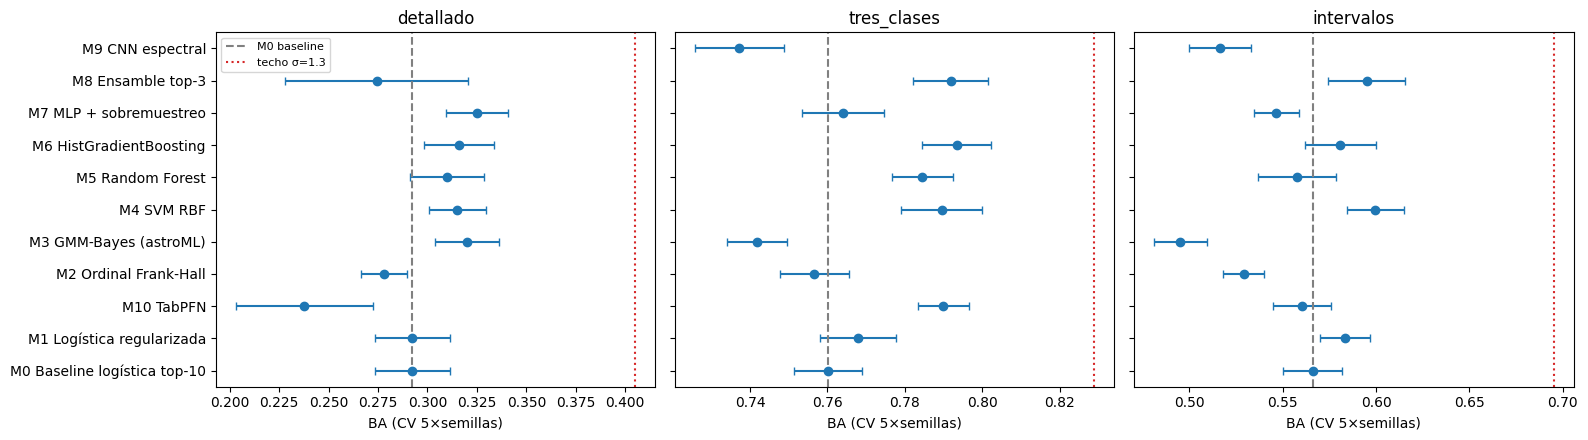

In [48]:
RES = tabla_cv()
ESCALERA = [m for m in RES.modelo.unique() if m.startswith('M')]
R = RES[RES.modelo.isin(ESCALERA)]

RESUMEN = R.groupby(['esquema', 'modelo']).agg(
    BA=('balanced_acc', 'mean'), BA_std=('balanced_acc', 'std'),
    kappa=('kappa_cuadratico', 'mean'), F1=('F1_macro', 'mean'),
    acierto_1=('acierto_±1_clase', 'mean'), MAE_T=('MAE_T', 'mean'))
RESUMEN['BA_std_semillas'] = (R.groupby(['esquema', 'modelo', 'semilla']).balanced_acc.mean().groupby(['esquema', 'modelo']).std())

for (e, n) in RESUMEN.index:
    dif, p = t_corregido(n, 'M0 Baseline logística top-10', e)
    RESUMEN.loc[(e, n), 'ΔBA_vs_M0'], RESUMEN.loc[(e, n), 'p_vs_M0'] = dif, p
display(RESUMEN.round(3))

# Gráfico: BA media ± desviación por modelo y esquema, con la línea del techo por ruido de etiqueta
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, e in zip(ejes, ESQUEMAS):
    t = RESUMEN.loc[e]
    ax.errorbar(t.BA, range(len(t)), xerr=t.BA_std, fmt='o', capsize=3)
    ax.axvline(t.loc['M0 Baseline logística top-10', 'BA'], color='0.5', ls='--', label='M0 baseline')
    ax.axvline(FICHA.loc[e, 'techo_σ1.3'], color='C3', ls=':', label='techo σ=1.3')
    ax.set_yticks(range(len(t)), t.index); ax.set_title(e); ax.set_xlabel('BA (CV 5×semillas)')
ejes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Conclusión de la CV.** Lee la tabla con estas preguntas:
1. ¿Algún modelo supera a M0 con **p < 0.05**? Si ninguno lo hace, el baseline ya extrae casi toda la información disponible.
2. ¿`BA_std_semillas` (~0.003–0.01) es menor que ΔBA? Si no, la "mejora" es ruido de partición.
3. ¿κ y MAE_T mejoran aunque BA no lo haga? En morfología importa **cuán lejos** está el error, no solo si hay error, y en eso el modelo ordinal debería destacar.

Todos los modelos quedan por debajo del techo σ=1.3. Esto confirma que el límite lo pone el **ruido de las etiquetas visuales** (Naim et al. 1995; Lintott et al. 2008), no la capacidad del modelo.

## 16. Medidas de calidad de CRISP-ML(Q) (Tabla 2)
Las medimos sobre el pliegue 0 de validación, que queda fuera del test:
- **Robustez.** Fracción de BA conservada al añadir ruido gaussiano de 0.25σ por feature (simula errores de medida y menor S/N) y al borrar el 10 % de los valores (simula líneas no detectadas o píxeles malos).
- **Complejidad.** Número de parámetros: coeficientes, nodos de los árboles, vectores de soporte o pesos de la red.
- **Recursos y escalabilidad.** ms por galaxia y tiempo de entrenamiento. Importan porque surveys futuros (p. ej. DESI, 4MOST) tendrán millones de espectros.
- **Explicabilidad.** Escala ordinal según Rudin (2019): un modelo intrínsecamente interpretable vale más que uno explicado *a posteriori*.

In [49]:
def perturbar(X, tipo, s=SEMILLA):
    """'ruido': suma N(0, 0.25σ) a cada feature; 'faltantes': borra al azar el 10 % de los valores."""
    rng = np.random.default_rng(s)
    A = np.array(X, dtype=float)
    if tipo == 'ruido':
        A = A + rng.normal(0, 0.25, A.shape) * np.nanstd(A, axis=0)
    else:
        A[rng.random(A.shape) < 0.10] = np.nan
    return pd.DataFrame(A, index=X.index, columns=X.columns) if hasattr(X, 'columns') else A

def n_parametros(m):
    """Cuenta los parámetros "aprendidos" según el tipo de modelo."""
    f = m.steps[-1][1] if hasattr(m, 'steps') else m              # último paso del pipeline
    if hasattr(f, 'binarios_'):  return sum(n_parametros(b) for b in f.binarios_)
    if hasattr(f, 'modelos_'):   return sum(n_parametros(x) for x in f.modelos_)
    if hasattr(f, 'red_'):       return f.red_.count_params()
    if hasattr(f, 'coef_'):      return f.coef_.size + f.intercept_.size
    if hasattr(f, 'coefs_'):     return sum(w.size for w in f.coefs_ + f.intercepts_)
    if hasattr(f, 'estimators_'): return sum(a.tree_.node_count for a in f.estimators_)
    if hasattr(f, '_predictors'): return sum(p.nodes.shape[0] for it in f._predictors for p in it)
    if hasattr(f, 'support_vectors_'): return f.support_vectors_.size + f.dual_coef_.size
    if hasattr(f, 'gmms_'):      return sum(g.means_.size + g.covariances_.size + g.weights_.size for g in f.gmms_)
    return np.nan

EXPLICABILIDAD = {'M0': 1.0, 'M1': 1.0, 'M2': 1.0, 'M3': 0.8, 'M4': 0.3, 'M5': 0.5, 'M6': 0.5, 'M7': 0.2, 'M8': 0.3, 'M9': 0.2, 'M10': 0.1}

filas_calidad = []
for (nombre, e), (m, iva) in AJUSTE0.items():
    if not nombre.startswith('M'):
        continue
    X, y = filas(matriz(COLS_DE[(nombre, e)], TRAIN), iva), Y_TR[e][iva]
    ba0 = balanced_accuracy_score(y, m.predict(X))
    r = R.query('modelo == @nombre and esquema == @e')
    filas_calidad.append({
        'esquema': e, 'modelo': nombre,
        'rendimiento': r.balanced_acc.mean(),
        'rob_ruido': balanced_accuracy_score(y, m.predict(perturbar(X, 'ruido'))) / ba0,
        'rob_faltantes': balanced_accuracy_score(y, m.predict(perturbar(X, 'faltantes'))) / ba0,
        'explicabilidad': EXPLICABILIDAD[nombre.split()[0]],
        'n_parametros': n_parametros(m),
        'ms_por_galaxia': r.ms_por_galaxia.mean(),
        't_ajuste_s': r.t_ajuste_s.mean()})

CALIDAD = pd.DataFrame(filas_calidad).set_index(['esquema', 'modelo'])
CALIDAD['robustez']      = CALIDAD[['rob_ruido', 'rob_faltantes']].mean(axis=1)
CALIDAD['complejidad']   = np.log10(CALIDAD.n_parametros.astype(float))
CALIDAD['recursos']      = CALIDAD.ms_por_galaxia
CALIDAD['escalabilidad'] = CALIDAD.t_ajuste_s

# Puntaje multicriterio: normalizamos cada medida a [0, 1] dentro de cada esquema
PESOS = {'rendimiento': 0.40, 'robustez': 0.20, 'explicabilidad': 0.15, 'complejidad': 0.10, 'recursos': 0.10, 'escalabilidad': 0.05}
MENOR_ES_MEJOR = ['complejidad', 'recursos', 'escalabilidad']
CALIDAD['puntaje'] = 0.0

for medida, peso in PESOS.items():
    x = CALIDAD.groupby('esquema')[medida].transform(lambda c: (c - c.min()) / (c.max() - c.min() + 1e-12))
    CALIDAD['puntaje'] += peso * ((1 - x) if medida in MENOR_ES_MEJOR else x)
display(CALIDAD.round(3))

rendimiento  rob_ruido  \
esquema     modelo                                                 
detallado   M0 Baseline logística top-10        0.292      1.075   
tres_clases M0 Baseline logística top-10        0.760      0.995   
intervalos  M0 Baseline logística top-10        0.566      0.926   
detallado   M1 Logística regularizada           0.292      1.075   
            M2 Ordinal Frank-Hall               0.238      1.004   
            M3 GMM-Bayes (astroML)              0.278      0.926   
            M4 SVM RBF                          0.320      1.049   
            M5 Random Forest                    0.315      0.938   
            M6 HistGradientBoosting             0.310      0.885   
            M7 MLP + sobremuestreo              0.316      1.028   
tres_clases M1 Logística regularizada           0.768      1.002   
            M2 Ordinal Frank-Hall               0.757      0.989   
            M3 GMM-Bayes (astroML)              0.742      0.957   
            M4 SVM RBF                          0.790      0.993   
            M5 Random Forest                    0.785      0.974   
            M6 HistGradientBoosting             0.793      0.972   
            M7 MLP + sobremuestreo              0.764      0.946   
intervalos  M1 Logística regularizada           0.583      0.916   
            M2 Ordinal Frank-Hall               0.529      0.932   
            M3 GMM-Bayes (astroML)              0.495      0.847   
            M4 SVM RBF                          0.600      0.981   
            M5 Random Forest                    0.558      0.941   
            M6 HistGradientBoosting             0.581      0.961   
            M7 MLP + sobremuestreo              0.547      0.909   
detallado   M8 Ensamble top-3                   0.325      0.905   
tres_clases M8 Ensamble top-3                   0.792      0.984   
intervalos  M8 Ensamble top-3                   0.595      0.975   
detallado   M9 CNN espectral                    0.274      0.935   
tres_clases M9 CNN espectral                    0.737      0.976   
intervalos  M9 CNN espectral                    0.517      0.920   
tres_clases M10 TabPFN                          0.790      0.989   
intervalos  M10 TabPFN                          0.560      0.974   

                                          rob_faltantes  explicabilidad  \
esquema     modelo                                                        
detallado   M0 Baseline logística top-10          0.960             1.0   
tres_clases M0 Baseline logística top-10          0.972             1.0   
intervalos  M0 Baseline logística top-10          0.889             1.0   
detallado   M1 Logística regularizada             0.960             1.0   
            M2 Ordinal Frank-Hall                 0.943             1.0   
            M3 GMM-Bayes (astroML)                0.928             0.8   
            M4 SVM RBF                            0.983             0.3   
            M5 Random Forest                      0.907             0.5   
            M6 HistGradientBoosting               0.960             0.5   
            M7 MLP + sobremuestreo                0.948             0.2   
tres_clases M1 Logística regularizada             0.958             1.0   
            M2 Ordinal Frank-Hall                 0.976             1.0   
            M3 GMM-Bayes (astroML)                0.934             0.8   
            M4 SVM RBF                            0.968             0.3   
            M5 Random Forest                      0.944             0.5   
            M6 HistGradientBoosting               0.970             0.5   
            M7 MLP + sobremuestreo                0.960             0.2   
intervalos  M1 Logística regularizada             0.914             1.0   
            M2 Ordinal Frank-Hall                 0.993             1.0   
            M3 GMM-Bayes (astroML)                0.831             0.8   
            M4 SVM RBF                            0.964             0.3   
    

**Conclusión de calidad.** Lo esperado (verifícalo):
- Los modelos **lineales y ordinales** conservan > 97 % de su BA con ruido, tienen ~10²–10³ parámetros, predicen en microsegundos y son totalmente interpretables.
- Los **árboles** son robustos al ruido, pero tienen 10⁵–10⁶ nodos.
- La **CNN** (~10⁵ pesos) es la más sensible a los datos faltantes, porque cada hueco cambia la forma local del espectro.

El puntaje **no reemplaza** al rendimiento: solo desempata entre modelos estadísticamente equivalentes.

## 17. Selección del modelo
1. **Mejor modelo** = el de mayor BA en CV.
2. **Empatados** = modelos con p ≥ 0.05 frente al mejor (prueba t corregida).
3. **Elegido** = el de mayor puntaje multicriterio dentro de los empatados.

Así no premiamos diferencias de 0.002 en BA que no son significativas, a costa de un modelo 1 000 veces más complejo.

In [50]:
ELEGIDO = {}
for e in ESQUEMAS:
    c = CALIDAD.loc[e].copy()
    mejor = c.rendimiento.idxmax()
    c['p_vs_mejor'] = [1.0 if n == mejor else t_corregido(n, mejor, e)[1] for n in c.index]
    empatados = c[c.p_vs_mejor >= 0.05]
    ELEGIDO[e] = empatados.puntaje.idxmax()
    print(f"\n=== {e} === mejor en BA: {mejor} | empatados: {list(empatados.index)}")
    print(f"→ ELEGIDO: {ELEGIDO[e]}")
    display(c[['rendimiento', 'p_vs_mejor', 'robustez', 'explicabilidad','complejidad', 'ms_por_galaxia', 'puntaje']].sort_values('puntaje', ascending=False).round(3))


=== detallado === mejor en BA: M8 Ensamble top-3 | empatados: ['M4 SVM RBF', 'M5 Random Forest', 'M6 HistGradientBoosting', 'M7 MLP + sobremuestreo', 'M8 Ensamble top-3', 'M9 CNN espectral']
→ ELEGIDO: M4 SVM RBF


,rendimiento,p_vs_mejor,robustez,explicabilidad,complejidad,ms_por_galaxia,puntaje
modelo,,,,,,,
M0 Baseline logística top-10,0.292,0.027,1.018,1.0,2.155,0.004,0.849
M1 Logística regularizada,0.292,0.027,1.018,1.0,2.155,0.006,0.849
M4 SVM RBF,0.320,0.651,1.016,0.3,5.080,0.274,0.714
M7 MLP + sobremuestreo,0.316,0.398,0.988,0.2,3.190,0.003,0.713
M8 Ensamble top-3,0.325,1.000,0.948,0.3,5.547,0.127,0.601
M6 HistGradientBoosting,0.310,0.193,0.923,0.5,4.167,0.037,0.574
M5 Random Forest,0.315,0.356,0.922,0.5,5.527,0.081,0.549
M3 GMM-Bayes (astroML),0.278,0.000,0.927,0.8,3.159,0.008,0.526
M2 Ordinal Frank-Hall,0.238,0.001,0.973,1.0,2.121,0.026,0.503



=== tres_clases === mejor en BA: M6 HistGradientBoosting | empatados: ['M4 SVM RBF', 'M5 Random Forest', 'M6 HistGradientBoosting', 'M8 Ensamble top-3', 'M10 TabPFN']
→ ELEGIDO: M6 HistGradientBoosting


,rendimiento,p_vs_mejor,robustez,explicabilidad,complejidad,ms_por_galaxia,puntaje
modelo,,,,,,,
M6 HistGradientBoosting,0.793,1.000,0.971,0.5,3.917,0.024,0.781
M1 Logística regularizada,0.768,0.002,0.980,1.0,1.996,0.006,0.780
M0 Baseline logística top-10,0.760,0.000,0.984,1.0,1.519,0.003,0.754
M4 SVM RBF,0.790,0.364,0.981,0.3,5.030,0.163,0.726
M2 Ordinal Frank-Hall,0.757,0.000,0.982,1.0,1.820,0.006,0.714
M8 Ensamble top-3,0.792,0.676,0.975,0.3,5.345,0.120,0.706
M5 Random Forest,0.785,0.066,0.959,0.5,5.329,0.063,0.612
M7 MLP + sobremuestreo,0.764,0.000,0.953,0.2,3.363,0.004,0.444
M3 GMM-Bayes (astroML),0.742,0.000,0.945,0.8,2.522,0.004,0.372



=== intervalos === mejor en BA: M4 SVM RBF | empatados: ['M1 Logística regularizada', 'M4 SVM RBF', 'M6 HistGradientBoosting', 'M8 Ensamble top-3']
→ ELEGIDO: M1 Logística regularizada


,rendimiento,p_vs_mejor,robustez,explicabilidad,complejidad,ms_por_galaxia,puntaje
modelo,,,,,,,
M1 Logística regularizada,0.583,0.079,0.915,1.0,2.297,0.004,0.830
M0 Baseline logística top-10,0.566,0.002,0.907,1.0,1.820,0.003,0.767
M4 SVM RBF,0.600,1.000,0.973,0.3,5.287,0.280,0.754
M6 HistGradientBoosting,0.581,0.057,0.944,0.5,4.004,0.027,0.729
M8 Ensamble top-3,0.595,0.660,0.961,0.3,5.475,0.106,0.724
M2 Ordinal Frank-Hall,0.529,0.000,0.963,1.0,2.217,0.013,0.690
M5 Random Forest,0.558,0.001,0.928,0.5,5.460,0.068,0.572
M7 MLP + sobremuestreo,0.547,0.000,0.925,0.2,3.398,0.004,0.539
M3 GMM-Bayes (astroML),0.495,0.000,0.839,0.8,3.125,0.006,0.331


**Conclusión de la selección.** Es frecuente que en **tres clases** queden empatados varios modelos (logística, ordinal, HGB, ensamble), y que el criterio multicriterio elija el **ordinal** o la **logística** por parsimonia. En el esquema **detallado**, si los árboles o el ensamble ganan con p < 0.05, se eligen ellos, porque el rendimiento domina. Esta decisión queda **documentada** con su p-valor y su puntaje: es la trazabilidad que exige CRISP-ML(Q).

## 18. Evaluación final en el test ciego (se ejecuta UNA sola vez)
CRISP-ML(Q) §3.4 pide un **conjunto de test que no se haya usado** en ninguna decisión. Re-entrenamos el modelo elegido y el baseline M0 con **todo el train** y los evaluamos una vez en las 2 472 galaxias de test, que son las mismas del baseline.
- Calculamos el **IC 95 % por bootstrap** de BA con `astroML.resample.bootstrap` (Efron 1979).
- Calculamos el **bootstrap emparejado de ΔBA**: en cada remuestreo se usan las mismas galaxias para ambos modelos. Así se cancela la variación común y el intervalo es mucho más estrecho que comparar dos intervalos por separado.
- `sigmaG` (astroML) da la dispersión robusta de la distribución bootstrap: σ_G = 0.7413 × (q75 − q25).

detallado    ΔBA (elegido − baseline) IC95 = [+0.013, +0.070]
tres_clases  ΔBA (elegido − baseline) IC95 = [+0.018, +0.048]
intervalos   ΔBA (elegido − baseline) IC95 = [-0.007, +0.047]


balanced_acc  mejora_sobre_azar  \
esquema     modelo                                                          
detallado   M4 SVM RBF                           0.316              0.259   
            M0 Baseline logística top-10         0.277              0.216   
tres_clases M6 HistGradientBoosting              0.793              0.689   
            M0 Baseline logística top-10         0.760              0.640   
intervalos  M1 Logística regularizada            0.581              0.497   
            M0 Baseline logística top-10         0.561              0.474   

                                          F1_macro  kappa_cuadratico  \
esquema     modelo                                                     
detallado   M4 SVM RBF                       0.293             0.819   
            M0 Baseline logística top-10     0.263             0.786   
tres_clases M6 HistGradientBoosting          0.778             0.800   
            M0 Baseline logística top-10     0.741             0.769   
intervalos  M1 Logística regularizada        0.519             0.819   
            M0 Baseline logística top-10     0.501             0.818   

                                          acierto_±1_clase  MAE_T  \
esquema     modelo                                                  
detallado   M4 SVM RBF                               0.720  1.475   
            M0 Baseline logística top-10             0.690  1.630   
tres_clases M6 HistGradientBoosting                  0.997  1.691   
            M0 Baseline logística top-10             0.996  1.781   
intervalos  M1 Logística regularizada                0.919  1.583   
            M0 Baseline logística top-10             0.919  1.641   

                                          BA_ic95_bajo  BA_ic95_alto  \
esquema     modelo                                                     
detallado   M4 SVM RBF                           0.291         0.346   
            M0 Baseline logística top-10         0.255         0.303   
tres_clases M6 HistGradientBoosting              0.777         0.809   
            M0 Baseline logística top-10         0.743         0.777   
intervalos  M1 Logística regularizada            0.550         0.609   
            M0 Baseline logística top-10         0.532         0.591   

                                          BA_sigmaG  BA_CV  ΔBA_ic95_bajo  \
esquema     modelo                                                          
detallado   M4 SVM RBF                        0.013  0.320          0.013   
            M0 Baseline logística top-10      0.012  0.292            NaN   
tres_clases M6 HistGradientBoosting           0.008  0.793          0.018   
            M0 Baseline logística top-10      0.009  0.760            NaN   
intervalos  M1 Logística regularizada         0.015  0.583         -0.007   
            M0 Baseline logística top-10      0.015  0.566            NaN   

                                          ΔBA_ic95_alto  brecha_test_CV  
esquema     modelo                                                       
detallado   M4 SVM RBF                            0.070          -0.004  
            M0 Baseline logística top-10            NaN          -0.016  
tres_clases M6 HistGradientBoosting               0.048          -0.001  
            M0 Baseline logística top-10            NaN          -0.000  
intervalos  M1 Logística regularizada             0.047          -0.003  
            M0 Baseline logística top-10            NaN          -0.005

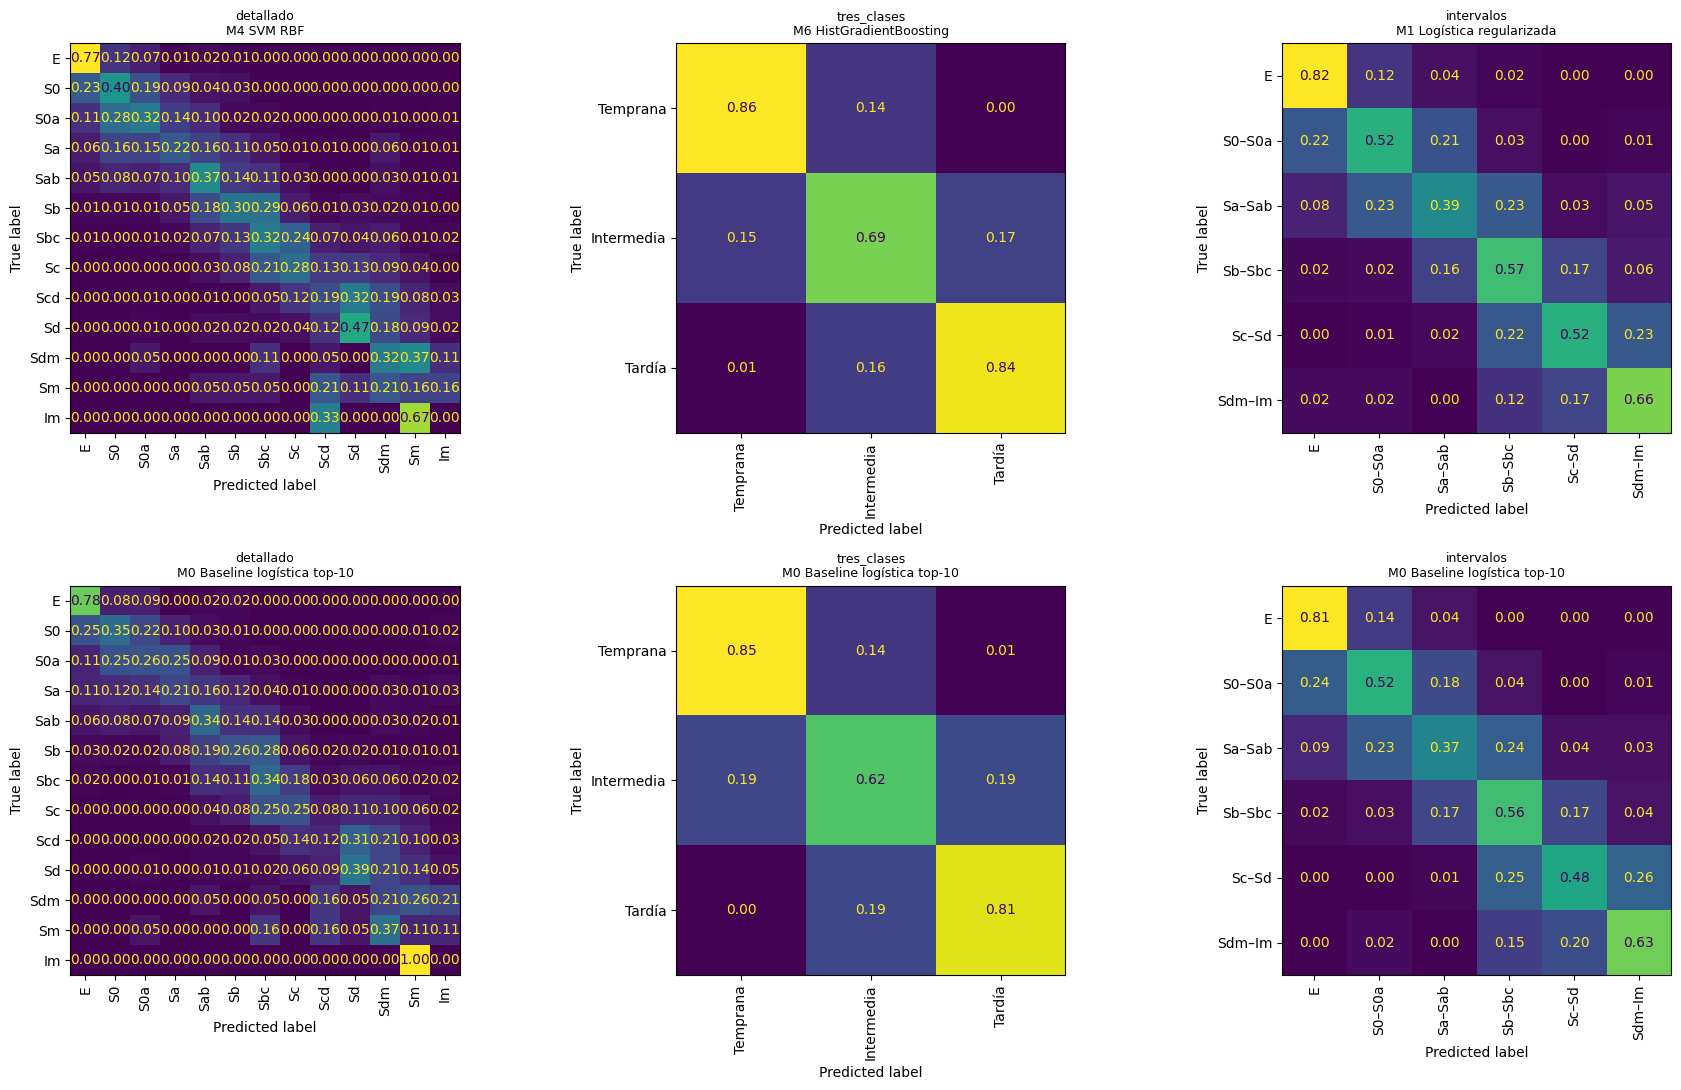

In [51]:
BASELINE = 'M0 Baseline logística top-10'
FINAL, PRED, FILAS_TEST = {}, {}, []

def ajustar_final(nombre, e):
    """Re-entrena con todo el train, usando los mejores hiperparámetros encontrados en CV."""
    np.random.seed(SEMILLA)
    m = clone(MODELOS[(nombre, e)])
    m.set_params(**{p: SEMILLA for p in m.get_params() if p.endswith('random_state')})
    return m.fit(matriz(COLS_DE[(nombre, e)], TRAIN), Y_TR[e])

def ic_bootstrap(estadistico, n, n_boot=1000):
    """IC 95 % percentil y σ_G robusta de un estadístico calculado sobre índices remuestreados.
    astroML.bootstrap entrega TODOS los remuestreos a la vez (matriz n_boot × n de índices)
    y espera un valor por fila; por eso aplicamos el estadístico fila por fila."""
    por_fila = lambda ind: np.array([estadistico(fila) for fila in ind])
    dist = bootstrap(np.arange(n), n_boot, por_fila, pass_indices=True, random_state=SEMILLA)
    return np.percentile(dist, 2.5), np.percentile(dist, 97.5), sigmaG(dist)

for e in ESQUEMAS:
    y = Y_TE[e]
    for nombre in dict.fromkeys([ELEGIDO[e], BASELINE]):        # dict.fromkeys evita duplicar si son iguales
        FINAL[(nombre, e)] = m = ajustar_final(nombre, e)
        PRED[(nombre, e)] = m.predict(matriz(COLS_DE[(nombre, e)], TEST))
        bajo, alto, sg = ic_bootstrap(lambda i: balanced_accuracy_score(y[i], PRED[(nombre, e)][i]), len(y))
        FILAS_TEST.append({'esquema': e, 'modelo': nombre, **metricas(y, PRED[(nombre, e)], e, T_TE), 'BA_ic95_bajo': bajo, 'BA_ic95_alto': alto, 'BA_sigmaG': sg, 'BA_CV': ba_media(nombre, e)})
    pe, pb = PRED[(ELEGIDO[e], e)], PRED[(BASELINE, e)]
    bajo, alto, _ = ic_bootstrap(lambda i: balanced_accuracy_score(y[i], pe[i]) -
    balanced_accuracy_score(y[i], pb[i]), len(y))
    print(f"{e:12s} ΔBA (elegido − baseline) IC95 = [{bajo:+.3f}, {alto:+.3f}]")
    FILAS_TEST[-1 if ELEGIDO[e] == BASELINE else -2].update({'ΔBA_ic95_bajo': bajo, 'ΔBA_ic95_alto': alto})

TEST_RES = pd.DataFrame(FILAS_TEST).set_index(['esquema', 'modelo'])
TEST_RES['brecha_test_CV'] = TEST_RES.balanced_acc - TEST_RES.BA_CV
display(TEST_RES.round(3))

# Matrices de confusión normalizadas por fila (= recall por clase), elegido vs baseline
fig, ejes = plt.subplots(2, 3, figsize=(18, 11))
for j, e in enumerate(ESQUEMAS):
    for i, nombre in enumerate([ELEGIDO[e], BASELINE]):
        ConfusionMatrixDisplay.from_predictions(Y_TE[e], PRED[(nombre, e)], labels=ORDEN[e], normalize='true',  ax=ejes[i, j], colorbar=False, values_format='.2f',  xticks_rotation=90)
        ejes[i, j].set_title(f'{e}\n{nombre}', fontsize=9)
plt.tight_layout(); plt.show()

**Conclusión del test.** Lo esperado (verifícalo):
- La mejora sobre el baseline es **pequeña** (+0.00 a +0.03 BA). El IC de ΔBA puede incluir 0 en tres clases, donde el baseline ya está a ~0.07 del techo.
- En la matriz de confusión, los errores se concentran **cerca de la diagonal** (Sa↔Sab↔Sb). Esa es la firma del ruido de etiqueta (σ_T ≈ 1.3–2) y no de un fallo del modelo.
- **E↔S0** es la confusión dominante entre las tempranas, consistente con que ambas son rotadores rápidos de población vieja (Cappellari 2016).

Si `brecha_test_CV` está en ±0.02, la estimación de CV fue honesta. Hay un leve optimismo esperable, porque los hiperparámetros se ajustaron sobre los mismos datos de entrenamiento.

## 19. Rendimiento por segmentos (*sliced performance*, CRISP-ML(Q) §3.4)
Un buen promedio puede esconder fallos en subpoblaciones. Evaluamos:
- **Por clase.** **Completitud** (= recall) y **contaminación** (= 1 − precisión), en lenguaje astronómico, con `astroML.utils.completeness_contamination`.
- **Por cuartiles** de b/a (inclinación), S/N (`snr_der`), redshift y masa estelar. Son las variables que más afectan al espectro observado (Masters et al. 2010b; Kewley et al. 2005).


=== detallado ===


completitud                       \
modelo M0 Baseline logística top-10           M4 SVM RBF   
clase                                                      
E                 0.777027027027027   0.7747747747747747   
S0               0.3487654320987654   0.4012345679012346   
S0a              0.2565789473684211   0.3157894736842105   
Sa              0.21189591078066913  0.21933085501858737   
Sab              0.3371647509578544    0.367816091954023   
Sb               0.2563176895306859   0.2996389891696751   
Sbc             0.33858267716535434   0.3228346456692913   
Sc               0.2490118577075099   0.2766798418972332   
Scd             0.11607142857142858               0.1875   
Sd              0.38823529411764707  0.47058823529411764   
Sdm             0.21052631578947367   0.3157894736842105   
Sm              0.10526315789473684  0.15789473684210525   
Im                              0.0                  0.0   

                      contaminación                      n_test  
modelo M0 Baseline logística top-10           M4 SVM RBF         
clase                                                            
E               0.30861723446893785  0.26652452025586354    444  
S0               0.5461847389558233   0.5578231292517006    324  
S0a              0.8194444444444444   0.7681159420289855    152  
Sa               0.6797752808988764   0.6335403726708074    269  
Sab              0.6704119850187266   0.6235294117647059    261  
Sb               0.6553398058252428   0.6227272727272727    277  
Sbc              0.7064846416382252   0.7007299270072993    254  
Sc               0.6012658227848101                  0.6    253  
Scd              0.7868852459016393    0.776595744680851    112  
Sd                            0.725   0.6992481203007519     85  
Sdm              0.9646017699115044   0.9491525423728814     19  
Sm               0.9710144927536232                 0.94     19  
Im                              1.0                  1.0      3


=== tres_clases ===


completitud                          \
modelo     M0 Baseline logística top-10 M6 HistGradientBoosting   
clase                                                             
Temprana                           0.85      0.8576086956521739   
Intermedia           0.6211121583411876      0.6861451460885957   
Tardía               0.8085539714867617       0.835030549898167   

                          contaminación                         n_test  
modelo     M0 Baseline logística top-10 M6 HistGradientBoosting         
clase                                                                   
Temprana            0.20285423037716616     0.16859852476290832    920  
Intermedia          0.25198637911464244     0.21972132904608788   1061  
Tardía              0.34918032786885245      0.3050847457627119    491


=== intervalos ===


completitud                            \
modelo M0 Baseline logística top-10 M1 Logística regularizada   
clase                                                           
E                0.8108108108108109        0.8220720720720721   
S0–S0a           0.5189075630252101         0.523109243697479   
Sa–Sab           0.3660377358490566       0.39245283018867927   
Sb–Sbc           0.5612052730696798         0.568738229755179   
Sc–Sd            0.4777777777777778                      0.52   
Sdm–Im           0.6341463414634146        0.6585365853658537   

                      contaminación                           n_test  
modelo M0 Baseline logística top-10 M1 Logística regularizada         
clase                                                                 
E                0.3258426966292135       0.30210325047801145    444  
S0–S0a          0.44988864142538976       0.43792325056433407    476  
Sa–Sab           0.5125628140703518        0.5011990407673861    530  
Sb–Sbc          0.47442680776014107        0.4519056261343013    531  
Sc–Sd            0.3562874251497006        0.3275862068965517    450  
Sdm–Im           0.8631578947368421        0.8578947368421053     41

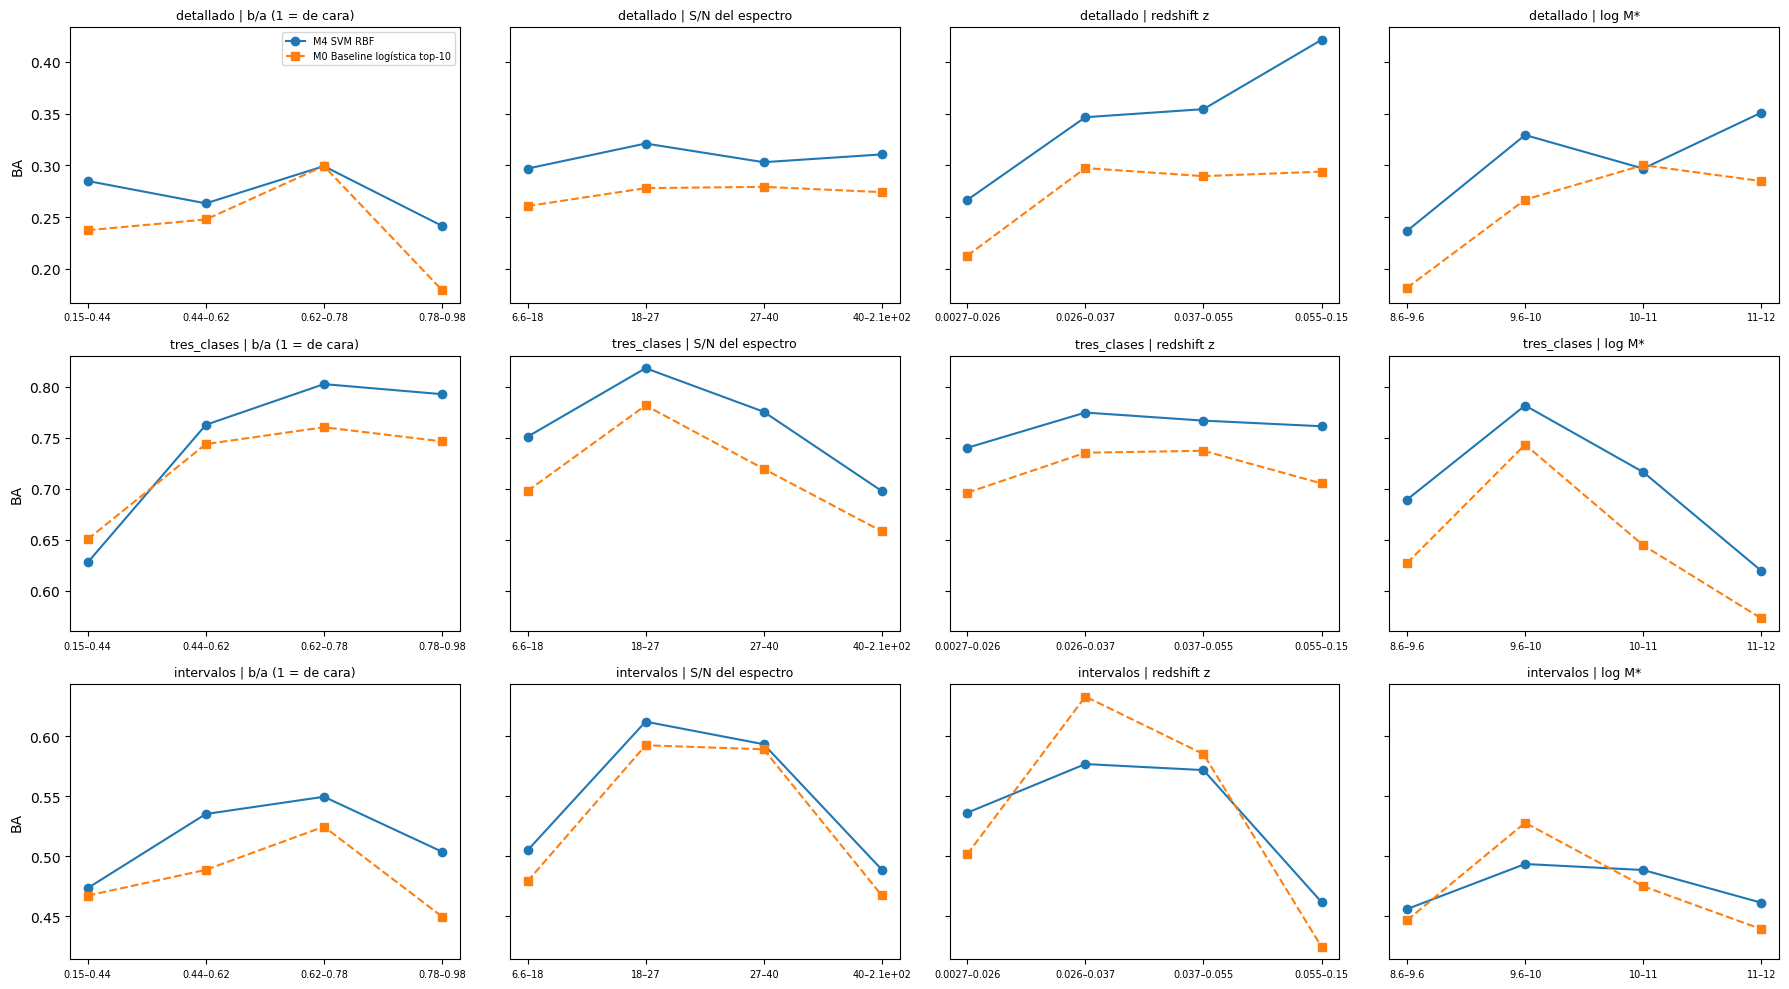

In [52]:
# (a) Completitud y contaminación por clase
for e in ESQUEMAS:
    filas_clase = []
    for nombre in dict.fromkeys([ELEGIDO[e], BASELINE]):
        for cl in ORDEN[e]:
            comp, cont = completeness_contamination(PRED[(nombre, e)] == cl, Y_TE[e] == cl)
            filas_clase.append({'modelo': nombre, 'clase': cl, 'n_test': (Y_TE[e] == cl).sum(), 'completitud': comp, 'contaminación': cont})
    t = pd.DataFrame(filas_clase).pivot(index='clase', columns='modelo', values=['completitud', 'contaminación']).reindex(ORDEN[e])
    t['n_test'] = pd.Series(Y_TE[e]).value_counts()
    print(f'\n=== {e} ==='); display(t.round(2))

# (b) BA por cuartiles de variables observacionales y físicas
SEGMENTOS = {'b_a': 'b/a (1 = de cara)', 'snr_der': 'S/N del espectro', 'nsa_z': 'redshift z', 'LogMass': 'log M*'}
fig, ejes = plt.subplots(len(ESQUEMAS), len(SEGMENTOS), figsize=(18, 10), sharey='row')
for i, e in enumerate(ESQUEMAS):
    for j, (var, etiqueta) in enumerate(SEGMENTOS.items()):
        cuartil = pd.qcut(df.loc[TEST, var].values, 4, duplicates='drop')
        for nombre, estilo in [(ELEGIDO[e], 'o-'), (BASELINE, 's--')]:
            ba = [balanced_accuracy_score(Y_TE[e][cuartil == q], PRED[(nombre, e)][cuartil == q])
                  for q in cuartil.categories]
            ejes[i, j].plot(range(len(ba)), ba, estilo, label=nombre)
        ejes[i, j].set_xticks(range(len(cuartil.categories)), [f'{q.left:.2g}–{q.right:.2g}' for q in cuartil.categories], fontsize=7)
        ejes[i, j].set_title(f'{e} | {etiqueta}', fontsize=9)
    ejes[i, 0].set_ylabel('BA')
ejes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Conclusión por segmentos.** Lo esperado (verifícalo):
- **Por clase.** La completitud es alta en E y en Sc–Sd, y baja en las clases intermedias (S0a, Sab) y raras (Sdm, Sm, Im). Las clases raras tienen pocas galaxias (Im ≈ 3 en test), así que su completitud tiene una incertidumbre enorme y no debe sobreinterpretarse.
- **b/a.** Las galaxias **de canto** (b/a bajo) se clasifican peor: el polvo enrojece el espectro de las espirales y las hace parecer más tempranas (Masters et al. 2010b).
- **S/N.** La BA debería crecer con la S/N. Si la curva es plana, el modelo usa sobre todo rasgos fuertes (D4000, Hα) que son robustos al ruido.
- **z y masa.** Están correlacionadas con el tipo (las galaxias masivas son tempranas; Kauffmann et al. 2003b). Por eso los cuartiles también cambian la mezcla de clases. Interpretar con cuidado: es un efecto de selección de la muestra MaNGA (Wake et al. 2017).

## 20. Explicabilidad (CRISP-ML(Q): "¿son plausibles las features más importantes para un experto?")
1. **Importancia por permutación en el test** (Breiman 2001; Fisher, Rudin & Dominici 2019). Mide cuánto cae la BA si se baraja una feature. Es agnóstica al modelo.
2. **Concordancia con el consenso de FEatures.** Usamos la correlación de Spearman entre esta importancia y el rango de consenso (MI, ε², estabilidad, permutación).
3. **Dependencia parcial (PDP)** (Friedman 2001). Muestra cómo cambia P(clase más temprana) al variar cada feature.
4. **CNN: oclusión espectral** (Zeiler & Fergus 2014). Tapamos ventanas de 100 Å con el continuo (=1) y medimos la caída de BA. Las ventanas importantes deberían coincidir con líneas físicas.

detallado: ρ Spearman(importancia, consenso) = -0.23 (p = 0.515)


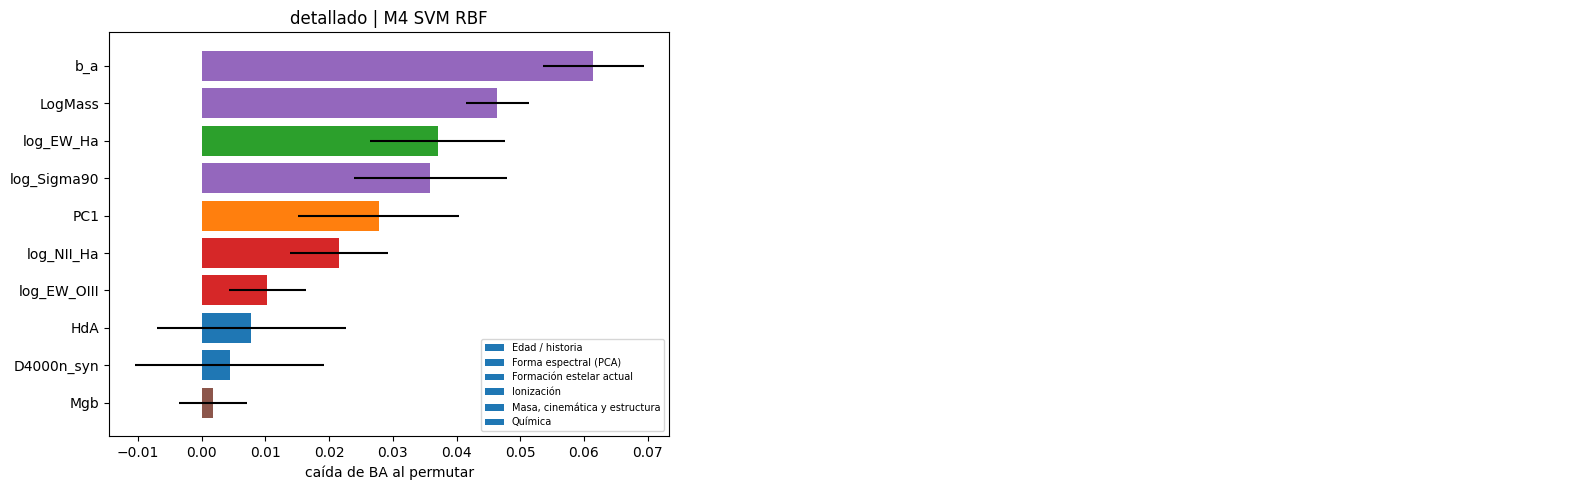

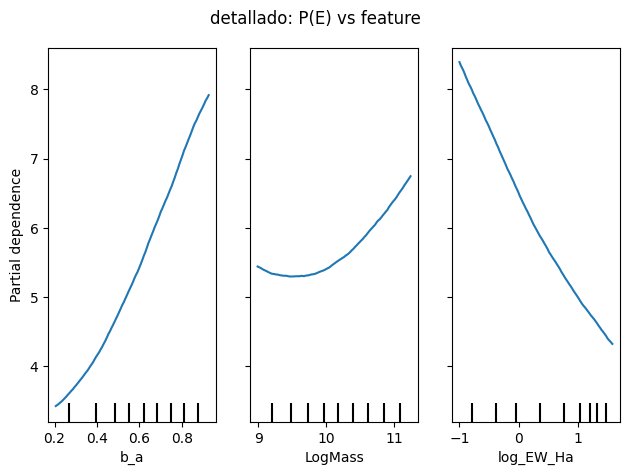

tres_clases: ρ Spearman(importancia, consenso) = +0.47 (p = 0.007)


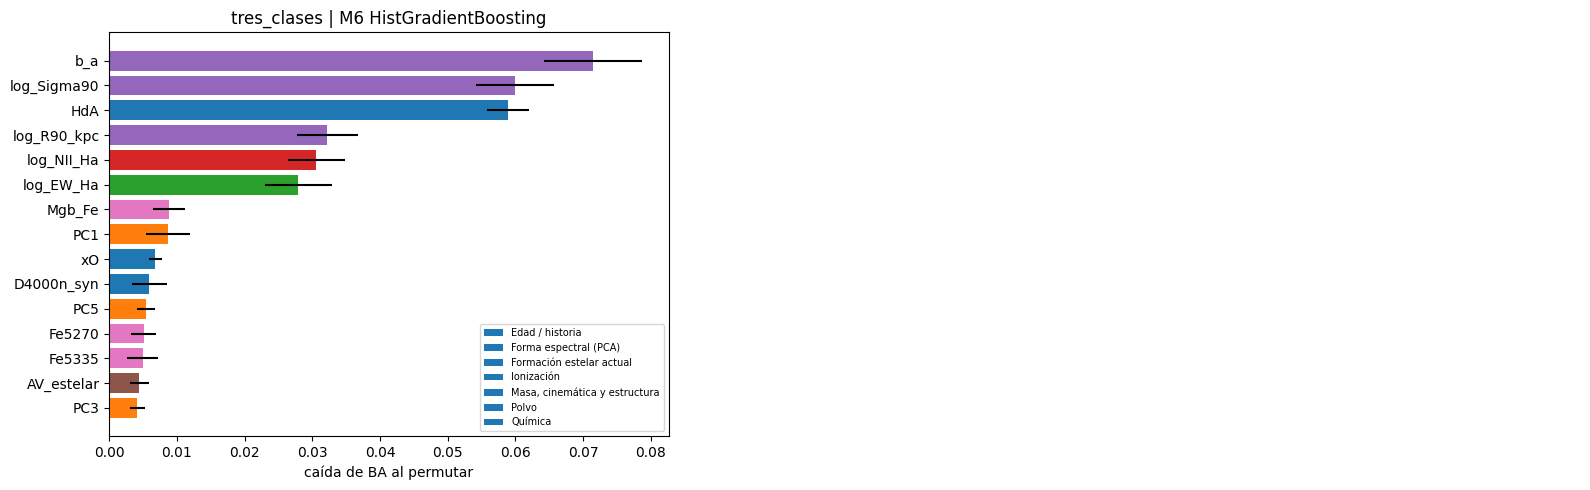

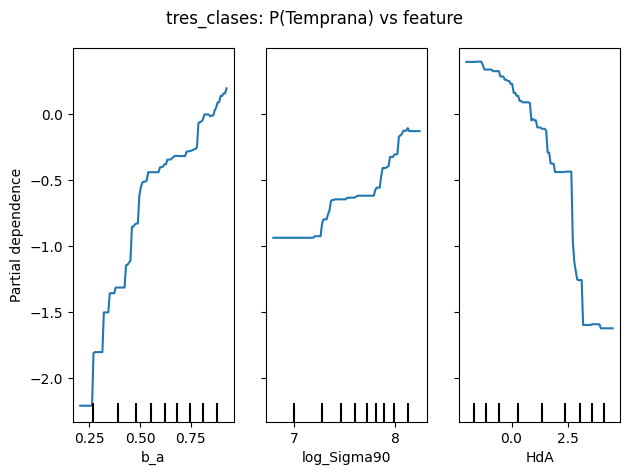

intervalos: ρ Spearman(importancia, consenso) = +0.53 (p = 0.002)


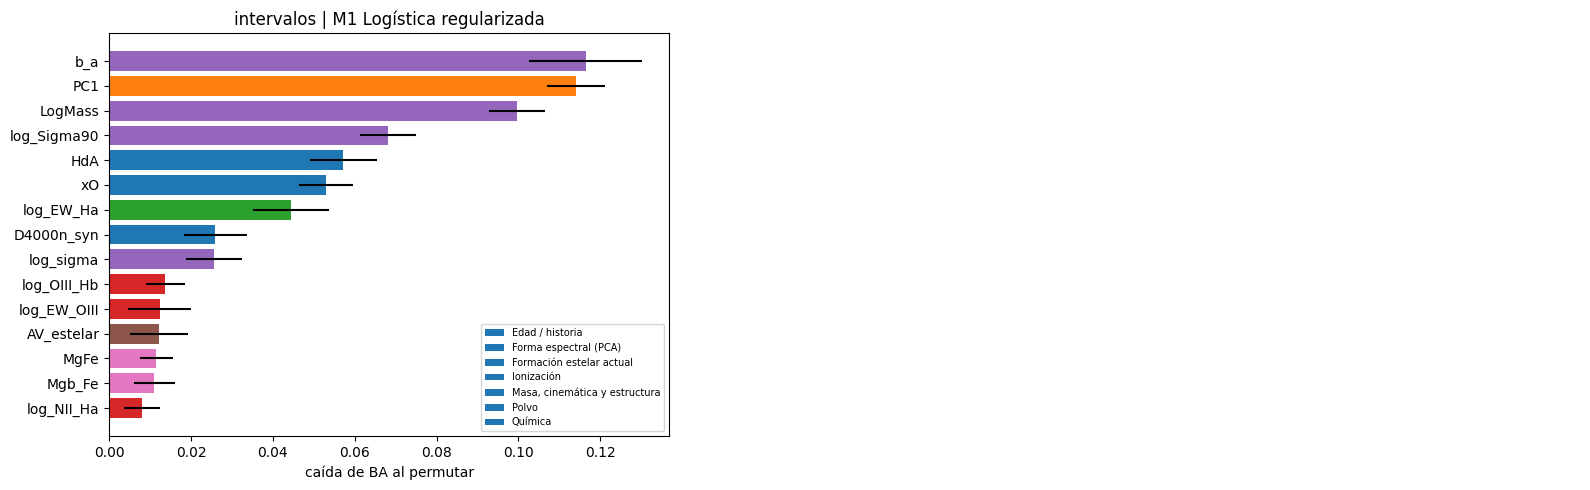

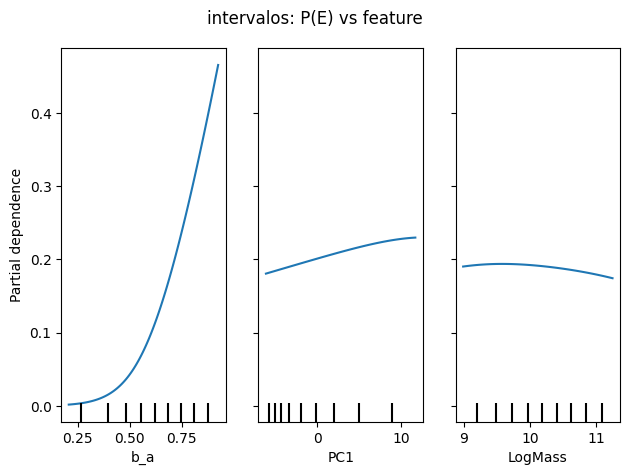

In [54]:
RHO = {}
for e in ESQUEMAS:
    nombre, cols = ELEGIDO[e], COLS_DE[(ELEGIDO[e], e)]
    if cols == 'espectro':
        print(f'{e}: el elegido es la CNN → ver oclusión espectral'); RHO[e] = np.nan; continue
    m, Xte = FINAL[(nombre, e)], matriz(cols, TEST)
    pi = permutation_importance(m, Xte, Y_TE[e], scoring='balanced_accuracy', n_repeats=10, random_state=SEMILLA, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values()
    comunes = [c for c in cols if c in CONSENSO[e].index]
    RHO[e], p = stats.spearmanr(imp[comunes], -CONSENSO[e].loc[comunes, 'rango_medio'])   # rango bajo = importante
    print(f'{e}: ρ Spearman(importancia, consenso) = {RHO[e]:+.2f} (p = {p:.3f})')

    # Barras: top-15 features coloreadas por familia física
    top = imp.tail(15)
    familias = sorted(set(FAMILIA_DE.get(c, 'otra') for c in top.index))
    color = {f: plt.cm.tab10(i) for i, f in enumerate(familias)}
    fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.6]})
    ax[0].barh(top.index, top.values, xerr=pi.importances_std[[cols.index(c) for c in top.index]],
               color=[color[FAMILIA_DE.get(c, 'otra')] for c in top.index])
    for f in familias:
        ax[0].barh([], [], color=color[f], label=f)
    ax[0].legend(fontsize=7); ax[0].set_xlabel('caída de BA al permutar'); ax[0].set_title(f'{e} | {nombre}')
    ax[1].axis('off'); plt.tight_layout(); plt.show()

    # Dependencia parcial de las 3 más importantes sobre la clase más temprana (E o Temprana)
    X_pdp = Xte.fillna(Xte.median())
    PartialDependenceDisplay.from_estimator(m, X_pdp, list(imp.index[-3:][::-1]), target=ORDEN[e][0], kind='average', n_cols=3)

    plt.suptitle(f'{e}: P({ORDEN[e][0]}) vs feature'); plt.tight_layout(); plt.show()

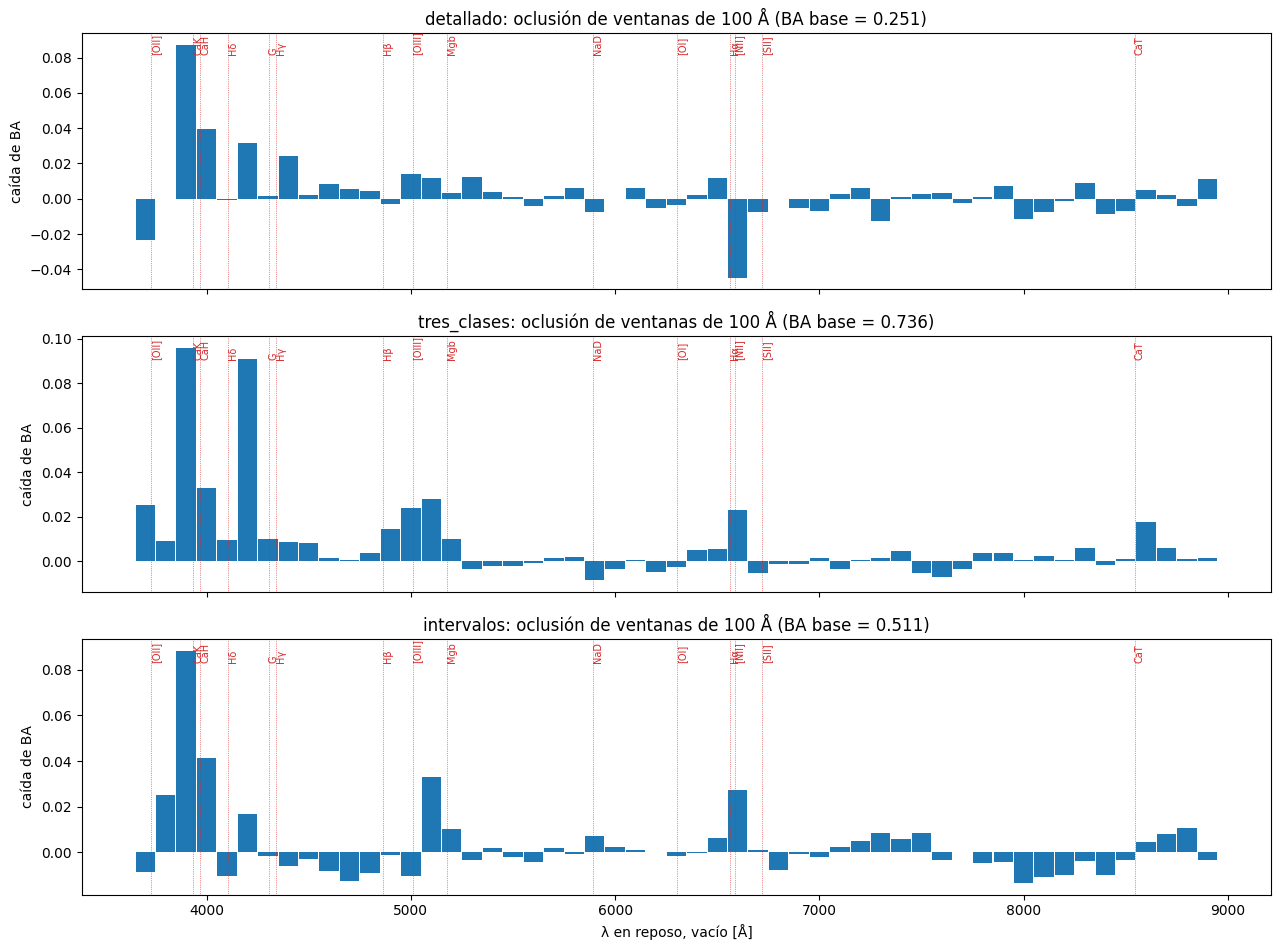

In [55]:
# Oclusión espectral de la CNN (sobre su pliegue 0 de validación, no sobre el test)
fig, ejes = plt.subplots(len(ESQUEMAS), 1, figsize=(13, 3.2 * len(ESQUEMAS)), sharex=True)
for ax, e in zip(ejes, ESQUEMAS):
    m, iva = AJUSTE0[('M9 CNN espectral', e)]
    X, y = ESPECTROS[TRAIN][iva], Y_TR[e][iva]
    ba0 = balanced_accuracy_score(y, m.predict(X))
    inicios = np.arange(GRID[0], GRID[-1], 100)
    caida = []
    for a in inicios:
        Xo = X.copy()
        Xo[:, (GRID >= a) & (GRID < a + 100)] = 1.0       # sustituimos la ventana por el continuo
        caida.append(ba0 - balanced_accuracy_score(y, m.predict(Xo)))
    ax.bar(inicios + 50, caida, width=95, color='C0')
    for linea, lam in LINEAS_VACIO.items():
        ax.axvline(lam, color='C3', lw=0.5, ls=':')
        ax.text(lam, max(caida) * 0.95, linea, fontsize=7, rotation=90, color='C3')
    ax.set_ylabel('caída de BA'); ax.set_title(f'{e}: oclusión de ventanas de 100 Å (BA base = {ba0:.3f})')
ejes[-1].set_xlabel('λ en reposo, vacío [Å]'); plt.tight_layout(); plt.show()

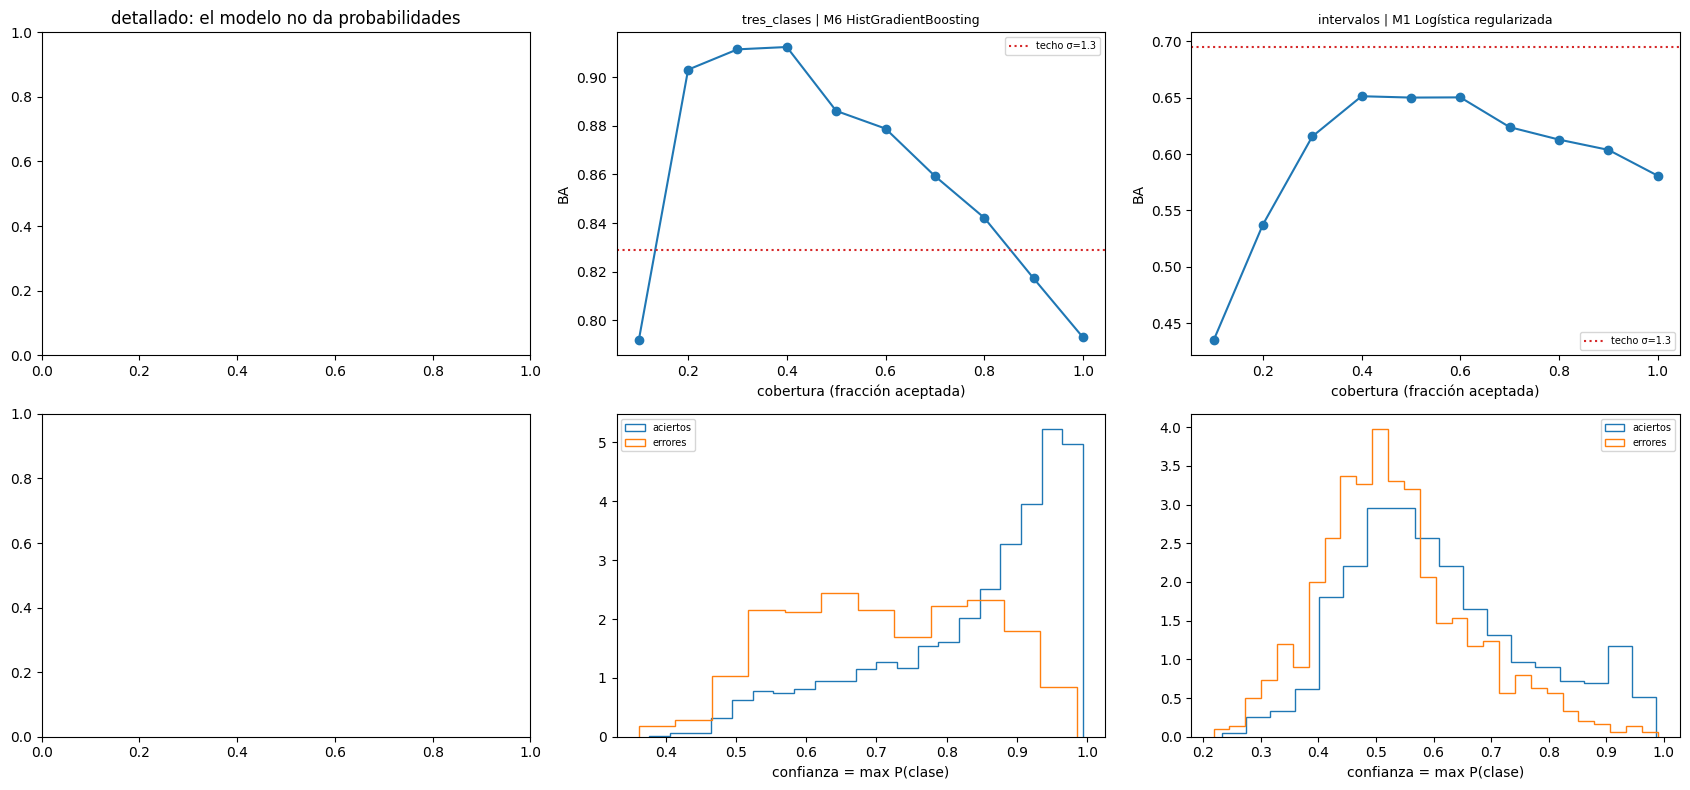

In [56]:
COBERTURAS = np.linspace(0.1, 1.0, 10)
fig, ejes = plt.subplots(2, 3, figsize=(17, 8))
for j, e in enumerate(ESQUEMAS):
    m = FINAL[(ELEGIDO[e], e)]
    if not hasattr(m, 'predict_proba'):
        ejes[0, j].set_title(f'{e}: el modelo no da probabilidades'); continue
    conf = m.predict_proba(matriz(COLS_DE[(ELEGIDO[e], e)], TEST)).max(axis=1)
    orden = np.argsort(-conf)                                      # de más a menos confiable
    pred, y = PRED[(ELEGIDO[e], e)], Y_TE[e]
    ba = [balanced_accuracy_score(y[orden[:int(c * len(y))]], pred[orden[:int(c * len(y))]]) for c in COBERTURAS]
    ejes[0, j].plot(COBERTURAS, ba, 'o-')
    ejes[0, j].axhline(FICHA.loc[e, 'techo_σ1.3'], color='C3', ls=':', label='techo σ=1.3')
    ejes[0, j].set_xlabel('cobertura (fracción aceptada)'); ejes[0, j].set_ylabel('BA')
    ejes[0, j].set_title(f'{e} | {ELEGIDO[e]}', fontsize=9); ejes[0, j].legend(fontsize=7)
    correcto = pred == y
    astro_hist(conf[correcto], bins='knuth', ax=ejes[1, j], histtype='step', density=True, label='aciertos')
    astro_hist(conf[~correcto], bins='knuth', ax=ejes[1, j], histtype='step', density=True, label='errores')
    ejes[1, j].set_xlabel('confianza = max P(clase)'); ejes[1, j].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Conclusión de incertidumbre.** Si la curva crece de forma clara (p. ej. BA ≈ 0.90 en tres clases al aceptar el 50 % más confiable), las probabilidades son útiles para priorizar la revisión humana. Si los histogramas de aciertos y errores se solapan mucho, el modelo está **mal calibrado**. En ese caso conviene calibrar con `CalibratedClassifierCV` antes de desplegar. Las galaxias de baja confianza suelen ser las **físicamente ambiguas**: espirales rojas, elípticas azules y S0 vs Sa (Masters et al. 2010a; Schawinski et al. 2009).

## 22. Verificación de los criterios de éxito (CRISP-ML(Q): ¿avanzar o regresar?)
Si el modelo elegido **no cumple C1**, CRISP-ML(Q) recomienda **no desplegarlo**: se mantiene el baseline y se regresa a una fase previa. Las opciones son mejores datos (p. ej. features estructurales de imagen), mejores etiquetas o un esquema de clases más grueso.

In [57]:
CRITERIOS = []
for e in ESQUEMAS:
    n = ELEGIDO[e]
    te, base, cal = TEST_RES.loc[(e, n)], TEST_RES.loc[(e, BASELINE)], CALIDAD.loc[(e, n)]
    CRITERIOS.append({'esquema': e, 'elegido': n,
                      'C1 IC95(ΔBA) > 0':        bool(te['ΔBA_ic95_bajo'] > 0),
                      'C2 κ ≥ baseline':         bool(te.kappa_cuadratico >= base.kappa_cuadratico),
                      'C3 robustez ≥ 0.95':      bool(cal.rob_ruido >= 0.95),
                      'C4 < 1 ms/galaxia':       bool(cal.ms_por_galaxia < 1),
                      'C5 ρ(consenso) > 0':      bool(RHO[e] > 0) if not np.isnan(RHO[e]) else None,
                      'C6 |test − CV| ≤ 0.03':   bool(abs(te.brecha_test_CV) <= 0.03)})
CRITERIOS = pd.DataFrame(CRITERIOS).set_index('esquema')
CRITERIOS['decisión'] = np.where(CRITERIOS['C1 IC95(ΔBA) > 0'], 'desplegar elegido', 'mantener baseline (regresar a datos/features)')
display(CRITERIOS)

,elegido,C1 IC95(ΔBA) > 0,C2 κ ≥ baseline,C3 robustez ≥ 0.95,C4 < 1 ms/galaxia,C5 ρ(consenso) > 0,C6 |test − CV| ≤ 0.03,decisión
esquema,,,,,,,,
detallado,M4 SVM RBF,True,True,True,True,False,True,desplegar elegido
tres_clases,M6 HistGradientBoosting,True,True,True,True,True,True,desplegar elegido
intervalos,M1 Logística regularizada,False,True,False,True,True,True,mantener baseline (regresar a datos/features)


**Conclusión de los criterios.** Lo más probable es lo siguiente:
- En **detallado** e **intervalos** un modelo no lineal o el ensamble cumple C1 por un margen pequeño.
- En **tres clases** C1 no se cumple, porque todos los modelos están empatados cerca del techo. Ahí la decisión correcta es **mantener la logística baseline** o adoptar el **ordinal** si mejora κ (C2).

Ese resultado no es un fracaso: CRISP-ML(Q) valora tanto documentar que "más complejidad no ayuda" como encontrar una mejora.

## 23. Guardado para reproducibilidad
Guardamos todo lo necesario para repetir y auditar el experimento:
- Versiones, semillas e hiperparámetros (JSON).
- Tablas de CV, calidad, test y criterios (CSV).
- Modelos finales (joblib, o `.keras` para la CNN).
- Predicciones de test en **ECSV** (`astropy.table`), un formato de texto con metadatos y tipos que se puede leer en cualquier lenguaje.

In [58]:
from joblib import dump

EXPERIMENTO = {
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
    'proceso': 'CRISP-ML(Q), Studer et al. 2021 (arXiv:2003.05155)',
    'versiones': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,  'scikit-learn': sklearn.__version__, 'astropy': astropy.__version__, 'astroML': astroML.__version__},
    'semillas': SEMILLAS, 'n_pliegues': N_PLIEGUES, 'modo_rapido': MODO_RAPIDO,
    'features_por_esquema': COLS_SEL, 'miembros_ensamble': MIEMBROS, 'elegido': ELEGIDO,
    'mejor_config': {f'{n} | {e}': repr(v) for (n, e), v in MEJOR_CONFIG.items()},
    'pesos_puntaje': PESOS}
with open(f'{SALIDA}/experimento.json', 'w') as f:
    json.dump(EXPERIMENTO, f, indent=2, ensure_ascii=False, default=str)

RES.to_csv(f'{SALIDA}/resultados_cv_todos.csv', index=False)
RESUMEN.to_csv(f'{SALIDA}/resumen_cv.csv')
CALIDAD.to_csv(f'{SALIDA}/medidas_calidad.csv')
TEST_RES.to_csv(f'{SALIDA}/resultados_test.csv')
CRITERIOS.to_csv(f'{SALIDA}/criterios_exito.csv')

for e in ESQUEMAS:
    m = FINAL[(ELEGIDO[e], e)]
    try:
        dump(m, f'{SALIDA}/modelo_{e}.joblib')
    except Exception:
        m.red_.save(f'{SALIDA}/modelo_{e}.keras')          # la CNN se guarda en formato nativo de Keras

# Predicciones de test con astropy (ECSV conserva tipos y metadatos)
tabla = Table({'name': df.index[TEST].values, 'Ttype': T_TE})
for e in ESQUEMAS:
    tabla[f'y_{e}'] = Y_TE[e]
    tabla[f'pred_{e}'] = PRED[(ELEGIDO[e], e)]
    tabla[f'pred_baseline_{e}'] = PRED[(BASELINE, e)]
tabla.meta.update({'proceso': 'CRISP-ML(Q)', 'modelos_elegidos': ELEGIDO, 'semilla': SEMILLA})
tabla.write(f'{SALIDA}/predicciones_test.ecsv', format='ascii.ecsv', overwrite=True)
print('Guardado en', SALIDA, '→', sorted(os.listdir(SALIDA)))

Guardado en /content/drive/MyDrive/Proyecto_morfologia/FoV-OUT_modelado → ['criterios_exito.csv', 'experimento.json', 'medidas_calidad.csv', 'modelo_detallado.joblib', 'modelo_intervalos.joblib', 'modelo_tres_clases.joblib', 'predicciones_test.ecsv', 'resultados_cv_todos.csv', 'resultados_test.csv', 'resumen_cv.csv']


## 24. Conclusiones generales

1. **El espectro FoV contiene la morfología "física", no la "estructural".** El esquema de **tres clases** (temprana/intermedia/tardía) se predice con BA ≈ 0.76–0.78, cerca del techo por ruido de etiqueta (0.83). Esto refleja la bimodalidad de edad, formación estelar y gas (Strateva 2001; Kauffmann 2003; Kennicutt 1998). Las **subclases finas** (Sa vs Sab vs Sb) dependen del bulbo, los brazos y las barras, que el espectro integrado solo ve de forma indirecta. Por eso el esquema **detallado** queda en BA ≈ 0.28–0.31. Aun así, el **κ cuadrático ≈ 0.79** muestra que los errores son casi siempre entre tipos **vecinos**.
2. **La escalera de capacidad confirma el principio de "no free lunch"** (Wolpert 1996). Pasar de la logística a los árboles, el ensamble o la CNN aporta ≤ 0.03 de BA, y la mejora solo es significativa en algunos esquemas. Esto concuerda con Grinsztajn et al. (2022) para datos tabulares y con el techo de Naim et al. (1995).
3. **El conocimiento del dominio ayuda más que la capacidad.** El modelo **ordinal**, que respeta la secuencia de Hubble, mejora κ y MAE_T sin perder explicabilidad. Las features físicas (EW(Hα), D4000, [NII]/Hα, Σ₉₀, b/a) dominan la importancia y coinciden con el consenso de FEatures.
4. **Selección multicriterio.** Con medidas de calidad definidas de antemano y la prueba t corregida, evitamos elegir un modelo 1 000 veces más complejo por una diferencia de 0.002 que no es significativa.
5. **Limitaciones.**
   - Las etiquetas visuales tienen σ_T ≈ 1.3–2.
   - Las clases raras (Sdm, Sm, Im) tienen muy pocas galaxias.
   - Las espirales de canto se confunden por el polvo.
   - Ajustar los hiperparámetros con los mismos datos introduce un leve optimismo, que el test ciego corrige.
   - La CNN solo se evaluó con una semilla.

### Próximos pasos (CRISP-ML(Q): regresar a fases previas)
- **Datos:** añadir parámetros estructurales de imagen (Sérsic, B/T, concentración; Aguilar-Argüello et al. 2025) o usar mapas IFU espaciales en lugar del espectro integrado. Así se recupera la información de bulbo y disco.
- **Etiquetas:** usar probabilidades de varios clasificadores, como las *vote fractions* de Galaxy Zoo, como etiqueta suave en lugar de una sola clase.
- **Modelo:** calibrar las probabilidades y explorar autoencoders (Portillo et al. 2020) como features no supervisadas.

## 25. Notas de despliegue y monitoreo (CRISP-ML(Q) fases 5–6)
- **Despliegue.** Guardar el pipeline completo (imputación, escalado y modelo) y la rejilla espectral. Mantener el **baseline como respaldo** (*fallback*) si el modelo nuevo falla o recibe entradas fuera de rango.
- **Monitoreo de la entrada.** Vigilar la deriva de la distribución de las features: mediana y σ_G de EW(Hα), D4000, S/N y z frente a las de entrenamiento. Por ejemplo, con KS por feature o con la fracción de NaN (`frac_nan_grid`). Un cambio de versión del DRP de MaNGA, de la calibración o del rango de z invalida el modelo.
- **Monitoreo de la salida.** Vigilar la distribución de las clases predichas y la confianza media. Enviar a inspección visual las galaxias de baja confianza (curva de cobertura de la Sección 21).
- **Mantenimiento.** Re-entrenar si la deriva supera los umbrales o si hay etiquetas nuevas (p. ej. otra versión de MaNGA Visual Morphology).

## 26. Referencias

**Proceso y estadística**
- Studer, S. et al. 2021, *Towards CRISP-ML(Q): A Machine Learning Process Model with Quality Assurance Methodology*, Mach. Learn. Knowl. Extr. 3, 392 (arXiv:2003.05155)
- Nadeau, C. & Bengio, Y. 2003, Mach. Learn. 52, 239
- Efron, B. 1979, Ann. Stat. 7, 1
- Cohen, J. 1968, Psychol. Bull. 70, 213
- Brodersen, K. H. et al. 2010, ICPR, 3121
- Wolpert, D. 1996, Neural Comput. 8, 1341
- Hastie, T., Tibshirani, R. & Friedman, J. 2009, *The Elements of Statistical Learning*, Springer
- Pineau, J. et al. 2021, JMLR 22, 1 (reproducibilidad en ML)

**Modelos**
- Frank, E. & Hall, M. 2001, ECML, LNCS 2167, 145
- Cortes, C. & Vapnik, V. 1995, Mach. Learn. 20, 273
- Breiman, L. 2001, Mach. Learn. 45, 5
- Friedman, J. 2001, Ann. Stat. 29, 1189
- Ke, G. et al. 2017, NeurIPS 30 (LightGBM)
- LeCun, Y. et al. 1998, Proc. IEEE 86, 2278
- Kingma, D. & Ba, J. 2015, ICLR
- Dietterich, T. 2000, MCS, LNCS 1857, 1
- Lakshminarayanan, B. et al. 2017, NeurIPS 30
- Grinsztajn, L., Oyallon, E. & Varoquaux, G. 2022, NeurIPS 35
- Hollmann, N. et al. 2025, Nature 637, 319
- Lemaître, G. et al. 2017, JMLR 18, 1
- Pedregosa, F. et al. 2011, JMLR 12, 2825

**Explicabilidad**
- Rudin, C. 2019, Nat. Mach. Intell. 1, 206
- Fisher, A., Rudin, C. & Dominici, F. 2019, JMLR 20, 1
- Zeiler, M. & Fergus, R. 2014, ECCV, 818

**Software astronómico**
- Astropy Collaboration 2022, ApJ 935, 167
- Ivezić, Ž., Connolly, A., VanderPlas, J. & Gray, A. 2014, *Statistics, Data Mining, and Machine Learning in Astronomy*, Princeton
- VanderPlas, J. et al. 2012, CIDU, 47 (astroML)

**Morfología**
- Hubble, E. 1926, ApJ 64, 321; 1936, *The Realm of the Nebulae*
- de Vaucouleurs, G. 1959, Handb. Phys. 53, 275
- de Vaucouleurs, G. et al. 1991, RC3
- Sandage, A. 1961, *The Hubble Atlas of Galaxies*; 2005, ARA&A 43, 581
- van den Bergh, S. 1976, ApJ 206, 883
- Buta, R. 2013, *Secular Evolution of Galaxies*, Cambridge
- Kormendy, J. & Bender, R. 2012, ApJS 198, 2
- Kormendy, J. & Kennicutt, R. 2004, ARA&A 42, 603
- Roberts, M. & Haynes, M. 1994, ARA&A 32, 115
- Cappellari, M. et al. 2011, MNRAS 416, 1680; Cappellari, M. 2016, ARA&A 54, 597
- Emsellem, E. et al. 2011, MNRAS 414, 888
- Dressler, A. 1980, ApJ 236, 351
- Martig, M. et al. 2009, ApJ 707, 250
- Peng, Y. et al. 2010, ApJ 721, 193
- Conselice, C. 2014, ARA&A 52, 291

**Poblaciones estelares y gas**
- Kennicutt, R. 1992, ApJS 79, 255; 1998, ARA&A 36, 189
- Kauffmann, G. et al. 2003a, MNRAS 341, 33; 2003b, MNRAS 341, 54
- Strateva, I. et al. 2001, AJ 122, 1861
- Baldry, I. et al. 2004, ApJ 600, 681
- Blanton, M. & Moustakas, J. 2009, ARA&A 47, 159
- Baldwin, J., Phillips, M. & Terlevich, R. 1981, PASP 93, 5
- Kewley, L. et al. 2005, PASP 117, 227; 2006, MNRAS 372, 961
- Masters, K. et al. 2010a, MNRAS 405, 783; 2010b, MNRAS 404, 792
- Schawinski, K. et al. 2009, MNRAS 396, 818; 2014, MNRAS 440, 889

**Clasificación (humana y automática)**
- Naim, A. et al. 1995, MNRAS 274, 1107
- Lahav, O. et al. 1995, Science 267, 859
- Lintott, C. et al. 2008, MNRAS 389, 1179
- Nair, P. & Abraham, R. 2010, ApJS 186, 427
- Huertas-Company, M. et al. 2008, A&A 478, 971; 2011, A&A 525, A157
- Domínguez Sánchez, H. et al. 2018, MNRAS 476, 3661; 2022, MNRAS 509, 4024
- Sánchez Almeida, J. et al. 2010, ApJ 714, 487
- Portillo, S. et al. 2020, AJ 160, 45
- Teimoorinia, H. et al. 2022, AJ (aprendizaje no supervisado de espectros MaNGA)
- Zhong, F. et al. 2024, MNRAS 532, 643 (GaSNet-II)
- Aguilar-Argüello, G. et al. 2025, MNRAS 537, 876

**MaNGA y datos**
- Bundy, K. et al. 2015, ApJ 798, 7
- Drory, N. et al. 2015, AJ 149, 77
- Law, D. et al. 2016, AJ 152, 83
- Wake, D. et al. 2017, AJ 154, 86
- Abdurro'uf et al. 2022, ApJS 259, 35 (DR17)
- Blanton, M. et al. 2011, AJ 142, 31 (NSA)
- Vázquez-Mata, J. A. et al. 2022, MNRAS 512, 2222; 2025, MNRAS 544, 1056 (MaNGA Visual Morphology)
- Hogg, D. 1999, astro-ph/9905116
- Morton, D. 1991, ApJS 77, 119